# Imports

In [82]:
import pandas as pd
import numpy as np
import seaborn as sns
import glob
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plt.rcParams['figure.figsize'] = [15, 8]

# Load data

In [83]:
DATA_DIR = '../data/first_batch/'
DEVICE_NUMBER = 2
#filename = 'df_TRB145-5_2022-10-01_2022-11-01.csv'

In [84]:
all_files = glob.glob(DATA_DIR + f"df_TRB145-{DEVICE_NUMBER}*.csv")


df_list = []

for filename in all_files:
    df = pd.read_csv(filename, index_col=0, header=0)
    df_list.append(df)

df = pd.concat(df_list, axis=0, ignore_index=True)
del df_list
df

,result,table,_time,L1_act_power,L1_app_power,L1_current,L1_react_power,L1_voltage,L2_act_power,L2_app_power,...,L3_act_power,L3_app_power,L3_current,L3_react_power,L3_voltage,grid_freq,powerfactor1,powerfactor2,powerfactor3,timestamp
0,_result,0,2022-08-29 15:17:42+00:00,0.097,0.099,0.44,0.019,236.000000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,50.029999,0.98,0.0,0.0,29/08/2022 17:17:42
1,_result,0,2022-08-29 15:17:42.001000+00:00,0.097,0.099,0.44,0.019,236.000000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,50.029999,0.98,0.0,0.0,29/08/2022 17:17:42
2,_result,0,2022-08-29 15:17:43+00:00,0.096,0.098,0.44,0.019,236.300003,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,50.040001,0.98,0.0,0.0,29/08/2022 17:17:43
3,_result,0,2022-08-29 15:17:45+00:00,0.096,0.098,0.44,0.019,236.300003,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,50.029999,0.98,0.0,0.0,29/08/2022 17:17:45
4,_result,0,2022-08-29 15:17:45.001000+00:00,0.096,0.098,0.44,0.019,236.300003,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,50.029999,0.98,0.0,0.0,29/08/2022 17:17:45
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13077543,_result,0,2023-05-30 19:46:46.001000+00:00,0.123,0.151,0.72,0.087,239.199997,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,50.000000,0.81,0.0,0.0,30/05/2023 21:46:46
13077544,_result,0,2023-05-30 19:46:47+00:00,0.123,0.151,0.72,0.087,239.399994,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,50.000000,0.82,0.0,0.0,30/05/2023 21:46:47
13077545,_result,0,2023-05-30 19:46:49+00:00,0.124,0.152,0.72,0.088,239.399994,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,49.990002,0.82,0.0,0.0,30/05/2023 21:46:49
13077546,_result,0,2023-05-30 19:46:49.001000+00:00,0.124,0.152,0.72,0.088,239.399994,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,49.990002,0.82,0.0,0.0,30/05/2023 21:46:49


In [85]:
df.describe()

,table,L1_act_power,L1_app_power,L1_current,L1_react_power,L1_voltage,L2_act_power,L2_app_power,L2_current,L2_react_power,L2_voltage,L3_act_power,L3_app_power,L3_current,L3_react_power,L3_voltage,grid_freq,powerfactor1,powerfactor2,powerfactor3
count,13077548.0,1.307755e+07,1.307755e+07,1.307755e+07,1.307755e+07,1.307755e+07,13077548.0,13077548.0,13077548.0,13077548.0,13077548.0,13077548.0,13077548.0,13077548.0,13077548.0,1.307755e+07,1.307755e+07,1.307755e+07,13077548.0,13077548.0
mean,0.0,2.903352e-01,3.149484e-01,1.403153e+00,6.928583e-02,2.377499e+02,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7.646693e-09,5.000808e+01,7.736712e-01,0.0,0.0
std,0.0,6.173592e-01,6.139868e-01,2.585328e+00,7.681220e-02,1.643396e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.765266e-05,2.336119e-02,1.931431e-01,0.0,0.0
min,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2.293000e+02,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,4.984000e+01,0.000000e+00,0.0,0.0
25%,0.0,4.400000e-02,7.900000e-02,3.900000e-01,4.500000e-02,2.366000e+02,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,4.999000e+01,5.900000e-01,0.0,0.0
50%,0.0,9.400000e-02,1.030000e-01,4.900000e-01,6.300000e-02,2.377000e+02,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,5.001000e+01,8.500000e-01,0.0,0.0
75%,0.0,1.550000e-01,1.720000e-01,8.300000e-01,7.100000e-02,2.390000e+02,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,5.002000e+01,9.500000e-01,0.0,0.0
max,0.0,7.468000e+00,7.518000e+00,3.241000e+01,1.480000e+00,2.454000e+02,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.000000e-01,5.018000e+01,1.000000e+00,0.0,0.0


# Data preprocessing

## Drop useless columns

In [86]:
display(df['result'].unique(), df['table'].unique())
df = df.drop(columns=['result', 'table'])

array(['_result'], dtype=object)

array([0])

In [87]:
df.columns

Index(['_time', 'L1_act_power', 'L1_app_power', 'L1_current', 'L1_react_power',
       'L1_voltage', 'L2_act_power', 'L2_app_power', 'L2_current',
       'L2_react_power', 'L2_voltage', 'L3_act_power', 'L3_app_power',
       'L3_current', 'L3_react_power', 'L3_voltage', 'grid_freq',
       'powerfactor1', 'powerfactor2', 'powerfactor3', 'timestamp'],
      dtype='object')

Drop 0 std columns

In [88]:
cols_0_std = df.std(numeric_only=True)[df.std(numeric_only=True) == 0].index.values
print('Columns with 0 std:\n', cols_0_std)

df = df.drop(columns=cols_0_std)
print('\nColumns left:')
df.columns

Columns with 0 std:
 ['L2_act_power' 'L2_app_power' 'L2_current' 'L2_react_power' 'L2_voltage'
 'L3_act_power' 'L3_app_power' 'L3_current' 'L3_react_power'
 'powerfactor2' 'powerfactor3']

Columns left:


Index(['_time', 'L1_act_power', 'L1_app_power', 'L1_current', 'L1_react_power',
       'L1_voltage', 'L3_voltage', 'grid_freq', 'powerfactor1', 'timestamp'],
      dtype='object')

Devices **#1** and **#2** have `std==0` for **L2/powerfactor2** and **L3/powerfactor3** features

`L3_voltage` has only 1 different value, so also drop it (in **device #2**)

In [89]:
try:
    display(df['L3_voltage'].value_counts())
    if df['L3_voltage'].value_counts().shape[0] < 3:
        print('L3_voltage has only one value, dropping it')
        df = df.drop(columns=['L3_voltage'])
except KeyError:
    print('L3_voltage not found in df (already deleted in the previous stage)')

L3_voltage
0.0    13077547
0.1           1
Name: count, dtype: int64

L3_voltage has only one value, dropping it


## Missing values (without filled seconds)

In [90]:
pd.concat(
    [df.count(), df.isna().sum(), (df.isna().sum()/df.shape[0])*100],
    axis=1).rename(columns={0:'total', 1:'missing', 2:'missing_perc'})

,total,missing,missing_perc
_time,13077548,0,0.0
L1_act_power,13077548,0,0.0
L1_app_power,13077548,0,0.0
L1_current,13077548,0,0.0
L1_react_power,13077548,0,0.0
L1_voltage,13077548,0,0.0
grid_freq,13077548,0,0.0
powerfactor1,13077548,0,0.0
timestamp,13077548,0,0.0


## Time-index

In [91]:
df[['_time', 'timestamp']]

,_time,timestamp
0,2022-08-29 15:17:42+00:00,29/08/2022 17:17:42
1,2022-08-29 15:17:42.001000+00:00,29/08/2022 17:17:42
2,2022-08-29 15:17:43+00:00,29/08/2022 17:17:43
3,2022-08-29 15:17:45+00:00,29/08/2022 17:17:45
4,2022-08-29 15:17:45.001000+00:00,29/08/2022 17:17:45
...,...,...
13077543,2023-05-30 19:46:46.001000+00:00,30/05/2023 21:46:46
13077544,2023-05-30 19:46:47+00:00,30/05/2023 21:46:47
13077545,2023-05-30 19:46:49+00:00,30/05/2023 21:46:49
13077546,2023-05-30 19:46:49.001000+00:00,30/05/2023 21:46:49


`_time` issues:
- column has inconsistent time differences between rows;
- it's inconsistent with the `timestamp` column (they show different times for the same row);
- it takes too long to transform it to datetime. 

We decide to use the `timestamp` column as a more reliable time index. We drop the `_time` column.

In [92]:
df = df.drop(columns=['_time'])

If looking at `timestamp`, the $1/3$ of data are duplicates

In [93]:
df['timestamp'].duplicated().sum()

np.int64(4400875)

We can **drop** the duplicates or merge them by taking the **mean**

We decide to take the **mean**

In [94]:
# merge duplicated 'timestamp' rows by taking the mean of all values
df = df.groupby('timestamp').mean().reset_index()
df

,timestamp,L1_act_power,L1_app_power,L1_current,L1_react_power,L1_voltage,grid_freq,powerfactor1
0,01/02/2023 00:00:05,0.042,0.0860,0.42,0.074,237.750000,50.020000,0.495
1,01/02/2023 00:00:06,0.042,0.0850,0.42,0.074,237.699997,50.009998,0.500
2,01/02/2023 00:00:08,0.042,0.0855,0.42,0.074,237.699997,49.990002,0.495
3,01/02/2023 00:00:09,0.042,0.0860,0.42,0.074,237.699997,50.000000,0.500
4,01/02/2023 00:00:15,0.042,0.0860,0.43,0.075,237.600006,49.990002,0.500
...,...,...,...,...,...,...,...,...
8676668,31/08/2022 23:59:45,0.046,0.0640,0.34,0.044,241.399994,50.040001,0.720
8676669,31/08/2022 23:59:51,0.046,0.0650,0.34,0.045,241.500000,50.029999,0.720
8676670,31/08/2022 23:59:53,0.047,0.0650,0.35,0.044,241.500000,50.040001,0.730
8676671,31/08/2022 23:59:54,0.047,0.0650,0.35,0.044,241.500000,50.049999,0.730


Transform `timestamp` to datetime and use as index

In [95]:
df['timestamp'] = pd.to_datetime(df['timestamp'], format='%d/%m/%Y %H:%M:%S')
df = df.sort_values(by='timestamp')
df

,timestamp,L1_act_power,L1_app_power,L1_current,L1_react_power,L1_voltage,grid_freq,powerfactor1
2597943,2022-08-10 17:24:51,0.0560,0.075,0.42,0.0480,238.800003,50.029999,0.76
2597944,2022-08-10 17:24:56,0.0580,0.077,0.43,0.0490,238.800003,50.009998,0.76
2597945,2022-08-10 17:24:57,0.0585,0.077,0.43,0.0495,238.950005,50.009998,0.76
3889683,2022-08-15 13:52:51,0.1120,0.114,0.52,0.0220,237.800003,50.020000,0.98
3889684,2022-08-15 13:52:52,0.1120,0.114,0.52,0.0220,237.699997,50.020000,0.98
...,...,...,...,...,...,...,...,...
8474282,2023-05-30 21:46:45,0.1240,0.152,0.72,0.0880,239.199997,50.000000,0.81
8474283,2023-05-30 21:46:46,0.1230,0.151,0.72,0.0870,239.199997,50.000000,0.81
8474284,2023-05-30 21:46:47,0.1230,0.151,0.72,0.0870,239.399994,50.000000,0.82
8474285,2023-05-30 21:46:49,0.1240,0.152,0.72,0.0880,239.399994,49.990002,0.82


## Time range

In [96]:
print('We have data from:', df['timestamp'].min(),
      '\nuntil:', df['timestamp'].max())


We have data from: 2022-08-10 17:24:51 
until: 2023-05-30 21:46:50


## Time frequency
1-2 seconds between rows

In [97]:
df['timestamp'].diff().describe()

count                      8676672
mean     0 days 00:00:02.919427978
std      0 days 00:09:10.425020259
min                0 days 00:00:01
25%                0 days 00:00:01
50%                0 days 00:00:02
75%                0 days 00:00:05
max               14 days 13:14:09
Name: timestamp, dtype: object

## Missing seconds?

In [98]:
df.groupby(df['timestamp'].dt.floor('min')).count().describe()

,timestamp,L1_act_power,L1_app_power,L1_current,L1_react_power,L1_voltage,grid_freq,powerfactor1
count,363981.000000,363981.000000,363981.000000,363981.000000,363981.000000,363981.000000,363981.000000,363981.000000
mean,23.838258,23.838258,23.838258,23.838258,23.838258,23.838258,23.838258,23.838258
std,1.475979,1.475979,1.475979,1.475979,1.475979,1.475979,1.475979,1.475979
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000
50%,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000
75%,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000
max,36.000000,36.000000,36.000000,36.000000,36.000000,36.000000,36.000000,36.000000


- Only **24-30** seconds are available out of **60** on average for **each minute** for **devices #1, #2 and #3**
- Only **~40** seconds are available out of **60** on average for **each minute** for **devices #4** and **#5**

In [99]:
df.groupby(df['timestamp'].dt.floor('h')).count().describe()

,timestamp,L1_act_power,L1_app_power,L1_current,L1_react_power,L1_voltage,grid_freq,powerfactor1
count,6082.000000,6082.000000,6082.000000,6082.000000,6082.000000,6082.000000,6082.000000,6082.000000
mean,1426.615094,1426.615094,1426.615094,1426.615094,1426.615094,1426.615094,1426.615094,1426.615094
std,61.420077,61.420077,61.420077,61.420077,61.420077,61.420077,61.420077,61.420077
min,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
25%,1421.000000,1421.000000,1421.000000,1421.000000,1421.000000,1421.000000,1421.000000,1421.000000
50%,1432.000000,1432.000000,1432.000000,1432.000000,1432.000000,1432.000000,1432.000000,1432.000000
75%,1440.000000,1440.000000,1440.000000,1440.000000,1440.000000,1440.000000,1440.000000,1440.000000
max,1806.000000,1806.000000,1806.000000,1806.000000,1806.000000,1806.000000,1806.000000,1806.000000


- **1430-1700** seconds present out of **60*60=3600** seconds in **device #1, #2 and #3**
$$1700/3600=0.4722$$
- **~2300** seconds present out of **60*60=3600** seconds in **device #4** and **#5** 
$$2300/3600=0.6388$$

In [100]:
df = df.set_index('timestamp')

In [101]:
full_range = pd.DataFrame(
    index=pd.date_range(
        pd.DatetimeIndex(df.index).min(),
        pd.DatetimeIndex(df.index).max(), 
        freq='s'
    )
)
df = full_range.join(df, how='left').squeeze()

## Missing values with all seconds filled

In [102]:
pd.concat(
    [df.count(), df.isna().sum(), (df.isna().sum()/df.shape[0])*100],
    axis=1).rename(columns={0:'total', 1:'missing', 2:'missing_perc'})

,total,missing,missing_perc
L1_act_power,8676673,16654247,65.746712
L1_app_power,8676673,16654247,65.746712
L1_current,8676673,16654247,65.746712
L1_react_power,8676673,16654247,65.746712
L1_voltage,8676673,16654247,65.746712
grid_freq,8676673,16654247,65.746712
powerfactor1,8676673,16654247,65.746712


**Device #1**
```
                total	missing	    missing_perc
L1_act_power	3215454	6027729	    65.212698
```

**Device #2**
```
                total	missing	    missing_perc
L1_act_power	8676673	16654247	65.746712

```
**Device #3**
```
                total	missing	    missing_perc
L1_act_power	4299551	6259595	    59.281262
```

**Device #4**
```
                total	    missing	    missing_perc
L1_act_power	12606408	9279732	    42.400039
```

**Device #5**
```
                total	    missing	    missing_perc
L1_act_power	12605043	9280582	    42.404921
```

In [104]:
df = df.reset_index().rename(columns={'index': 'timestamp'})

# Data Analysis

## Correlation matrix

In [ ]:
sns.heatmap(df.drop(columns=['timestamp']).fillna('median').corr(), annot=True)
plt.title(f"Correlation Matrix")
plt.tight_layout()
plt.show()

## Feature Analysis by Phase

### L1 Phase Analysis

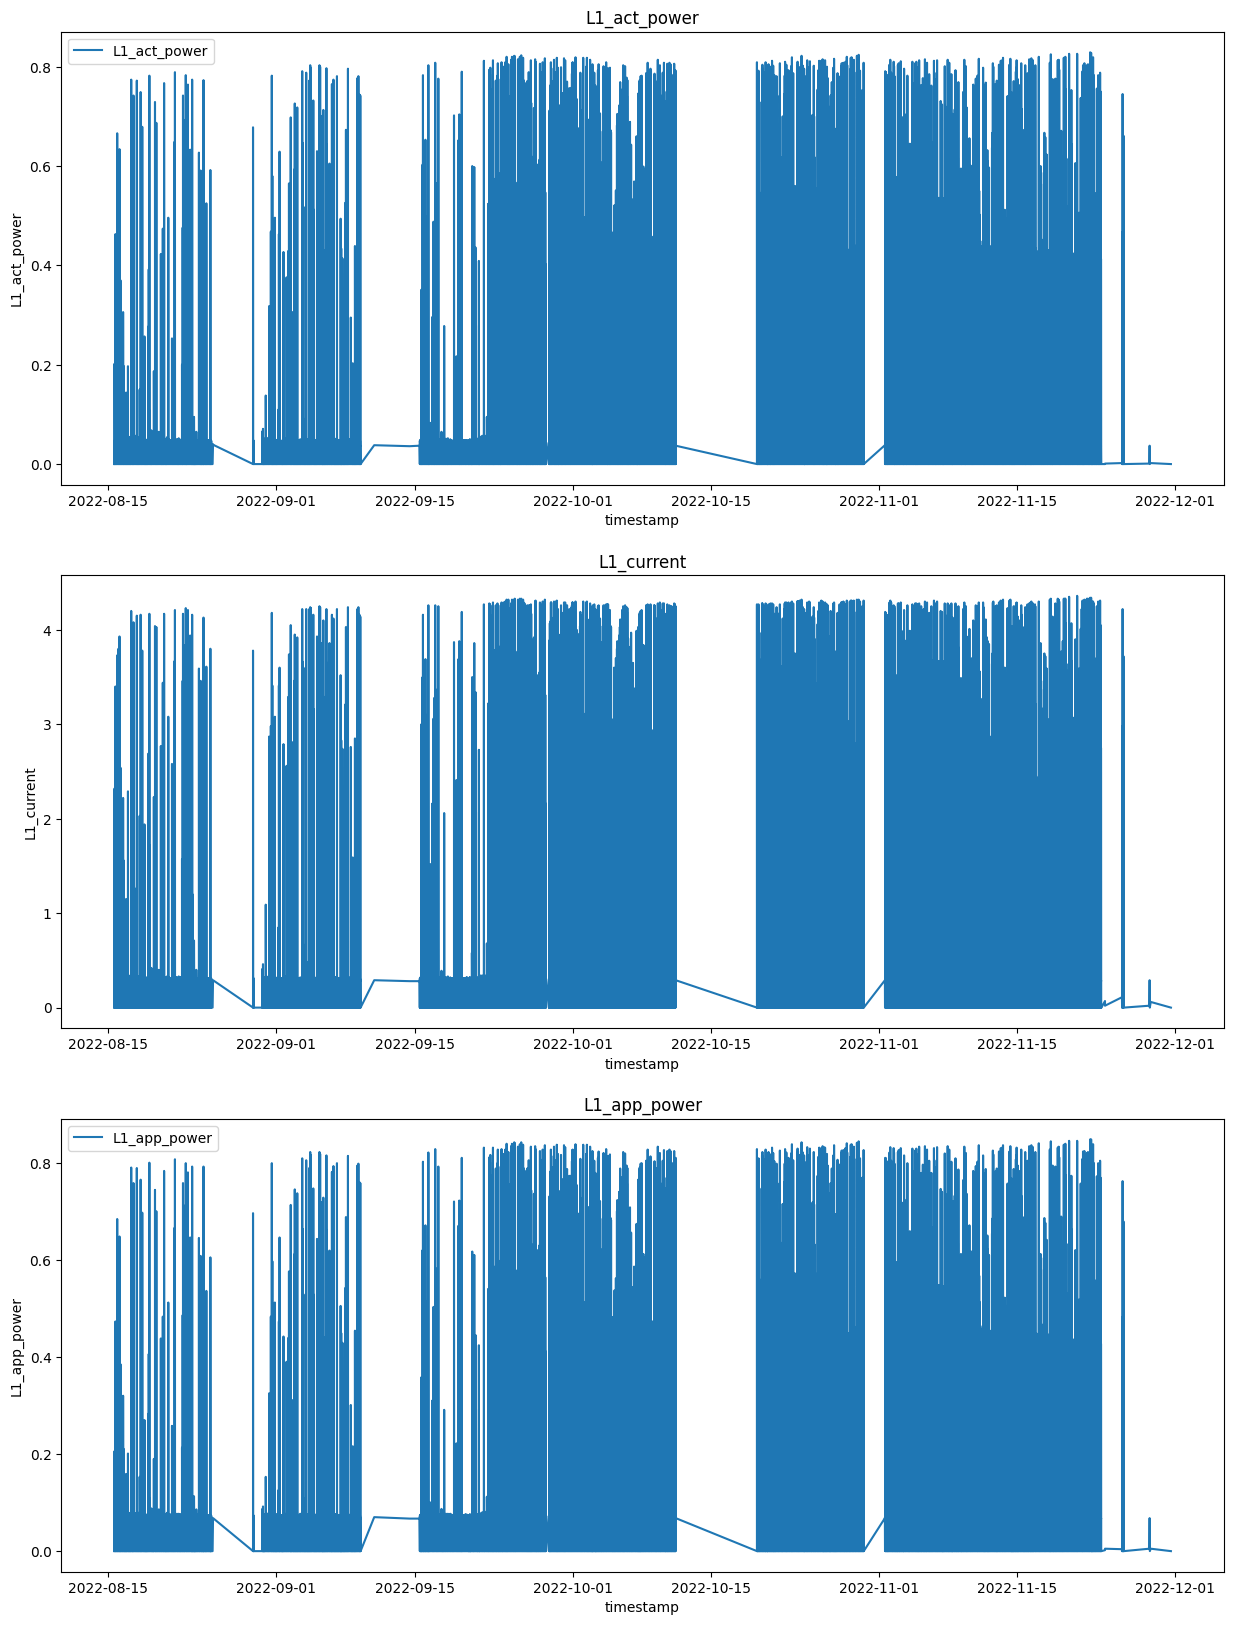

In [44]:
fig, axes = plt.subplots(3, 1, figsize=(15, 20))

sns.lineplot(data=df, x='timestamp', y='L1_act_power', label='L1_act_power', ax=axes[0])
axes[0].set_title('L1_act_power')
sns.lineplot(data=df, x='timestamp', y='L1_current', ax=axes[1])
axes[1].set_title('L1_current')
sns.lineplot(data=df, x='timestamp', y='L1_app_power', label='L1_app_power', ax=axes[2])
axes[2].set_title('L1_app_power');

We have missing values from around **2022-10-12 until 2022-10-20** for **all devices**

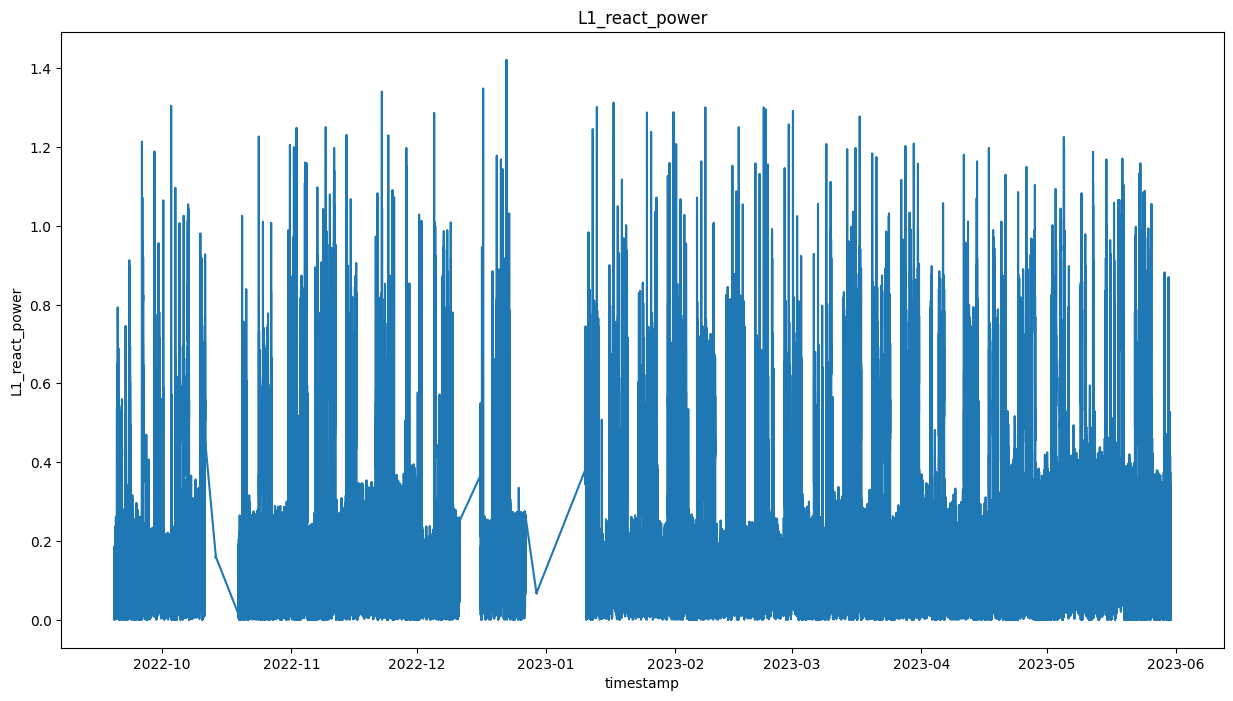

In [66]:
sns.lineplot(data=df, x='timestamp', y='L1_react_power')
plt.title('L1_react_power');

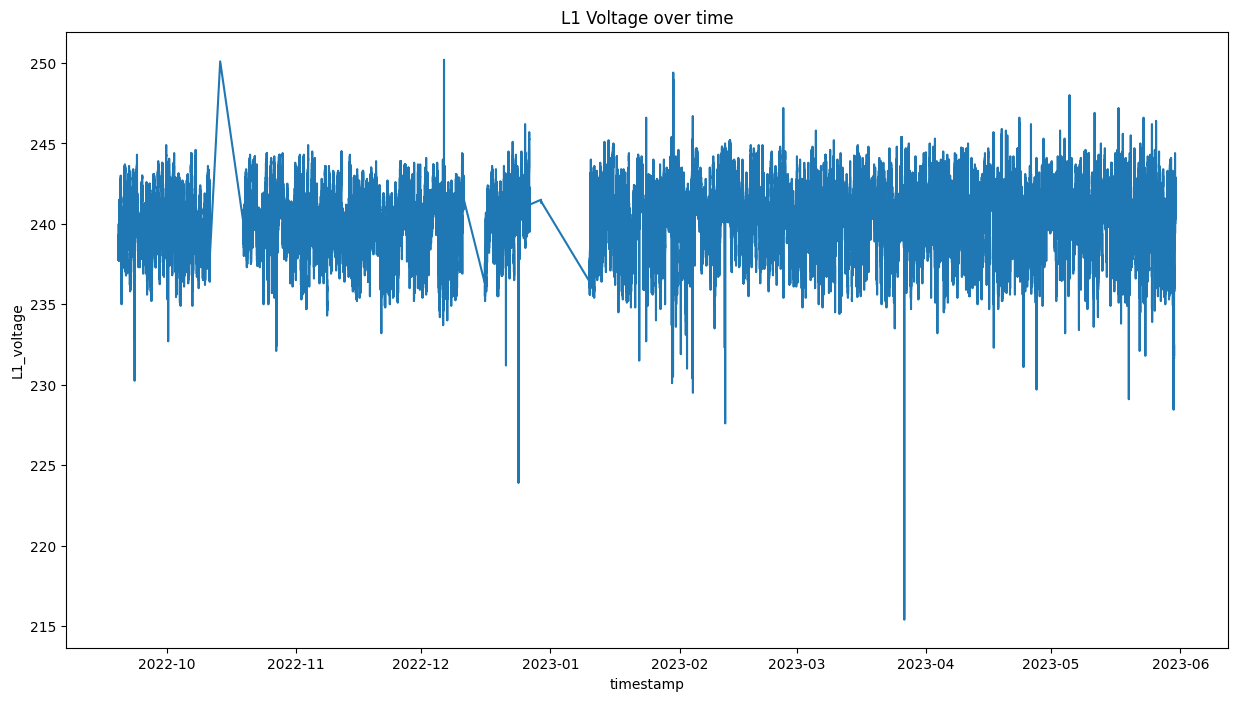

In [67]:
sns.lineplot(data=df, x='timestamp', y='L1_voltage')
plt.title('L1 Voltage over time');

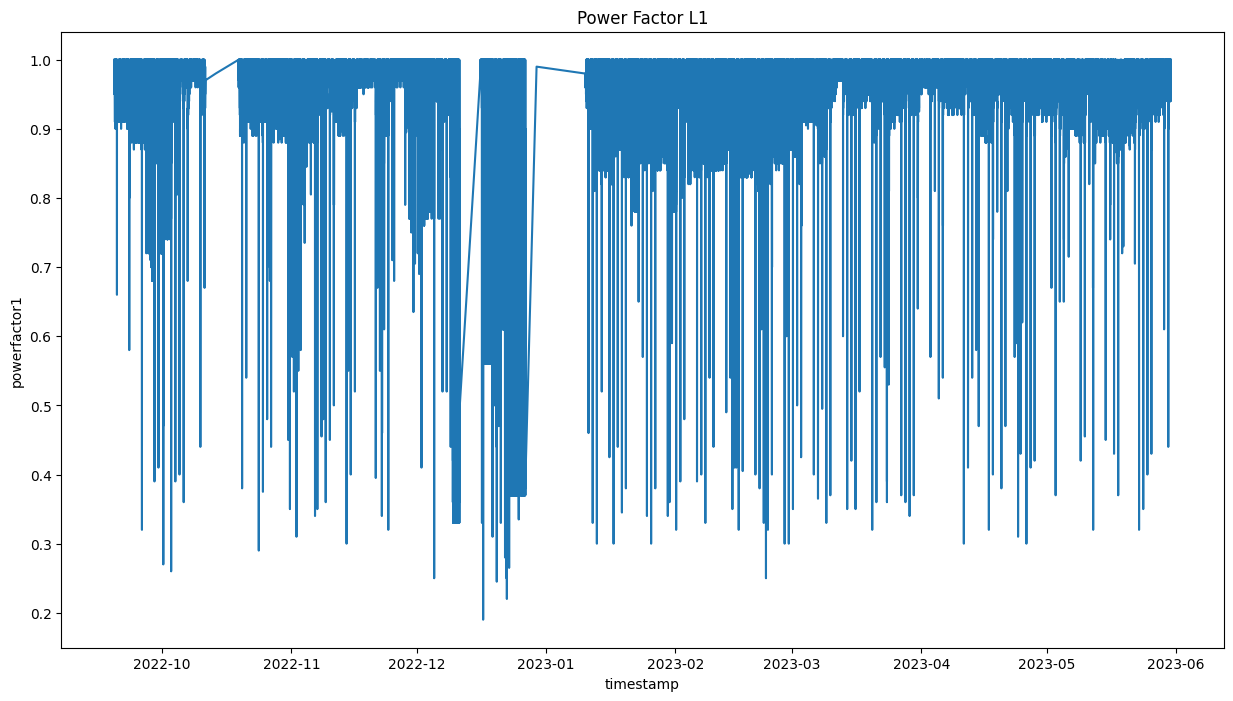

In [68]:
sns.lineplot(data=df, x='timestamp', y='powerfactor1')
plt.title('Power Factor L1');

### L2 Phase Analysis

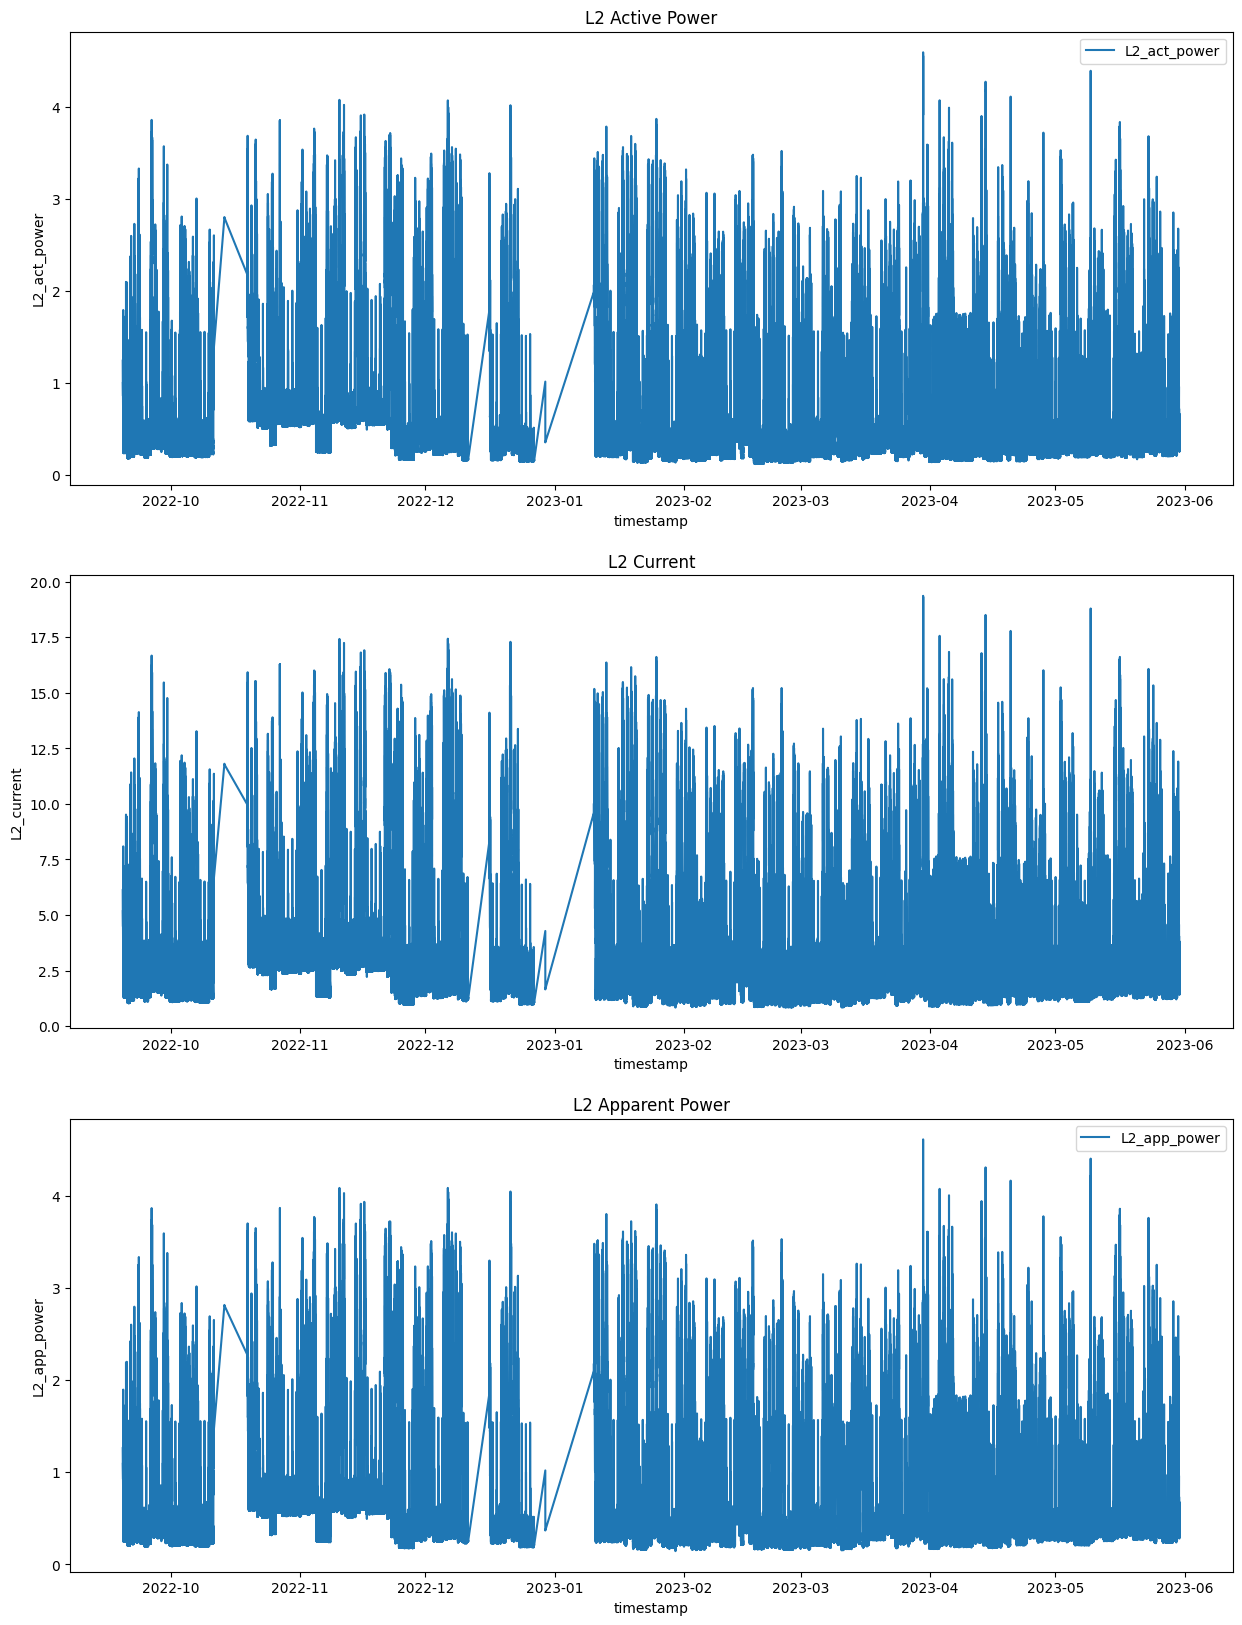

In [70]:
if df.columns.str.contains('L2').any():
    fig, axes = plt.subplots(3, 1, figsize=(15, 20))
    sns.lineplot(data=df, x='timestamp', y='L2_act_power', label='L2_act_power', ax=axes[0])
    axes[0].set_title('L2 Active Power')
    sns.lineplot(data=df, x='timestamp', y='L2_current', ax=axes[1])
    axes[1].set_title('L2 Current')
    sns.lineplot(data=df, x='timestamp', y='L2_app_power', label='L2_app_power', ax=axes[2])
    axes[2].set_title('L2 Apparent Power');
else:
    print('L2-phase columns for this device are uninformative (std = 0)')

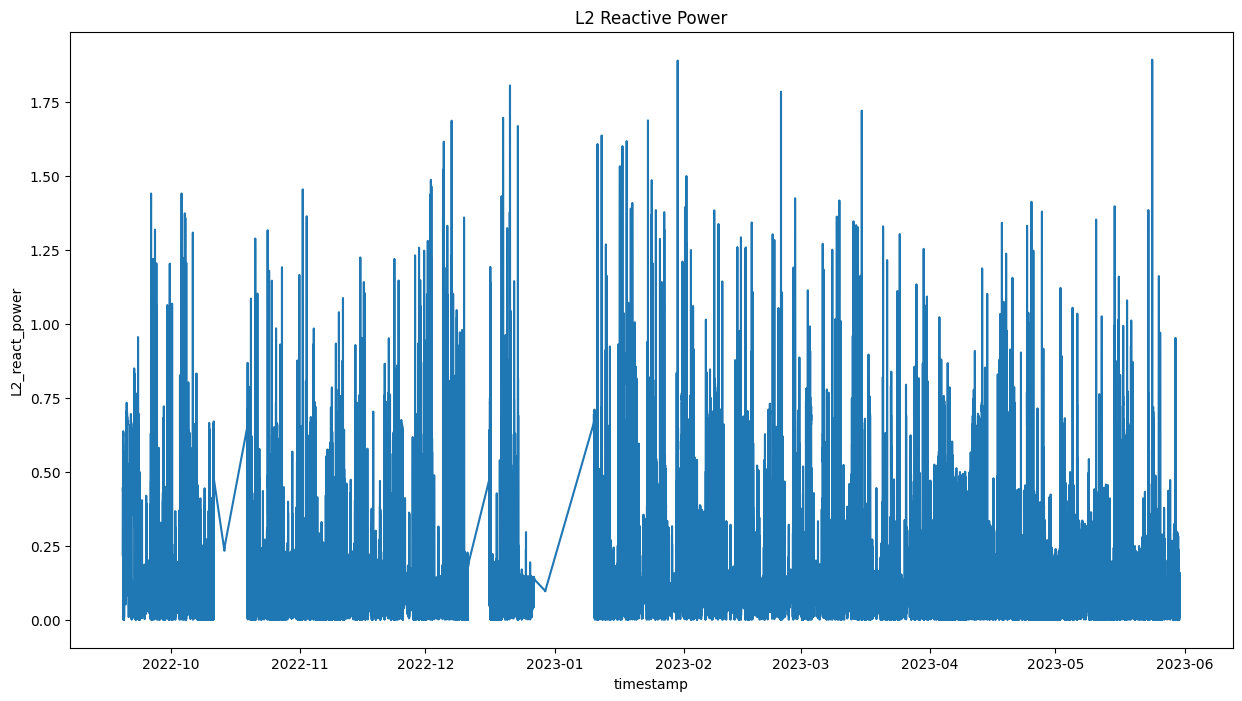

In [71]:
if df.columns.str.contains('L2').any():
    sns.lineplot(data=df, x='timestamp', y='L2_react_power')
    plt.title('L2 Reactive Power');
else:
    print('L2-phase columns for this device are uninformative (std = 0)')

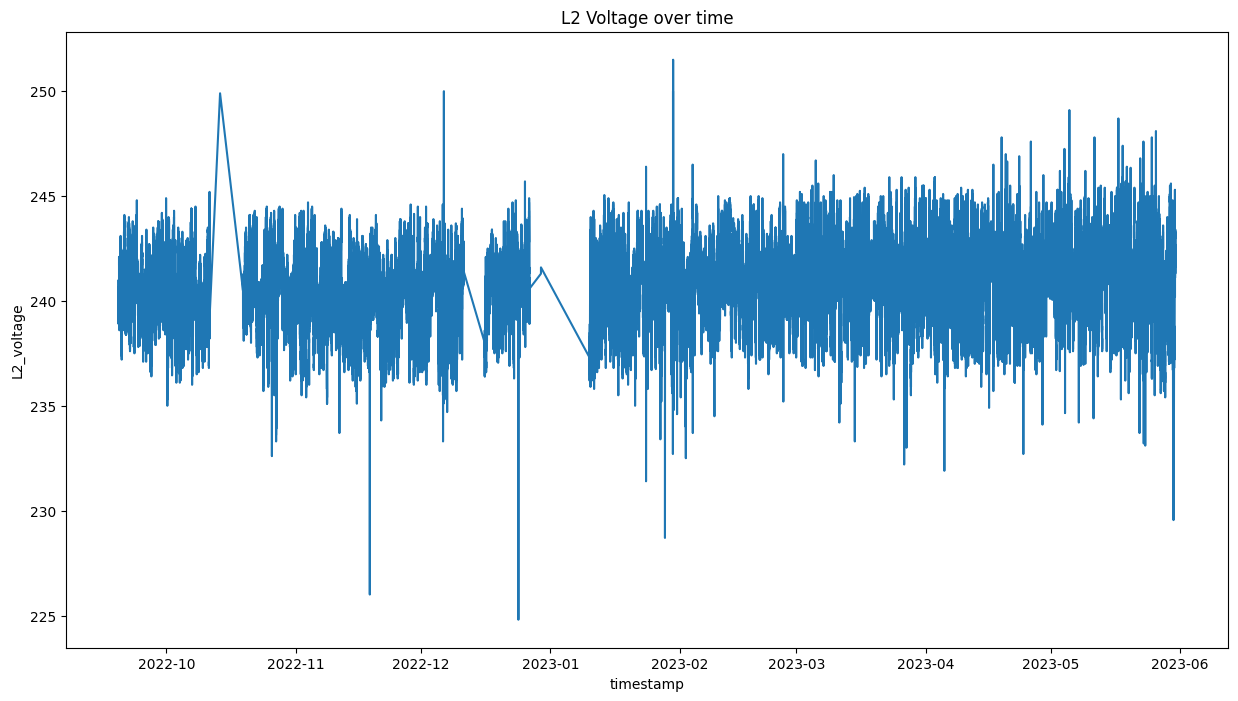

In [76]:
if df.columns.str.contains('L2').any():
    sns.lineplot(data=df, x='timestamp', y='L2_voltage')
    plt.title('L2 Voltage over time');
else:
    print('L2-phase columns for this device are uninformative (std = 0)')

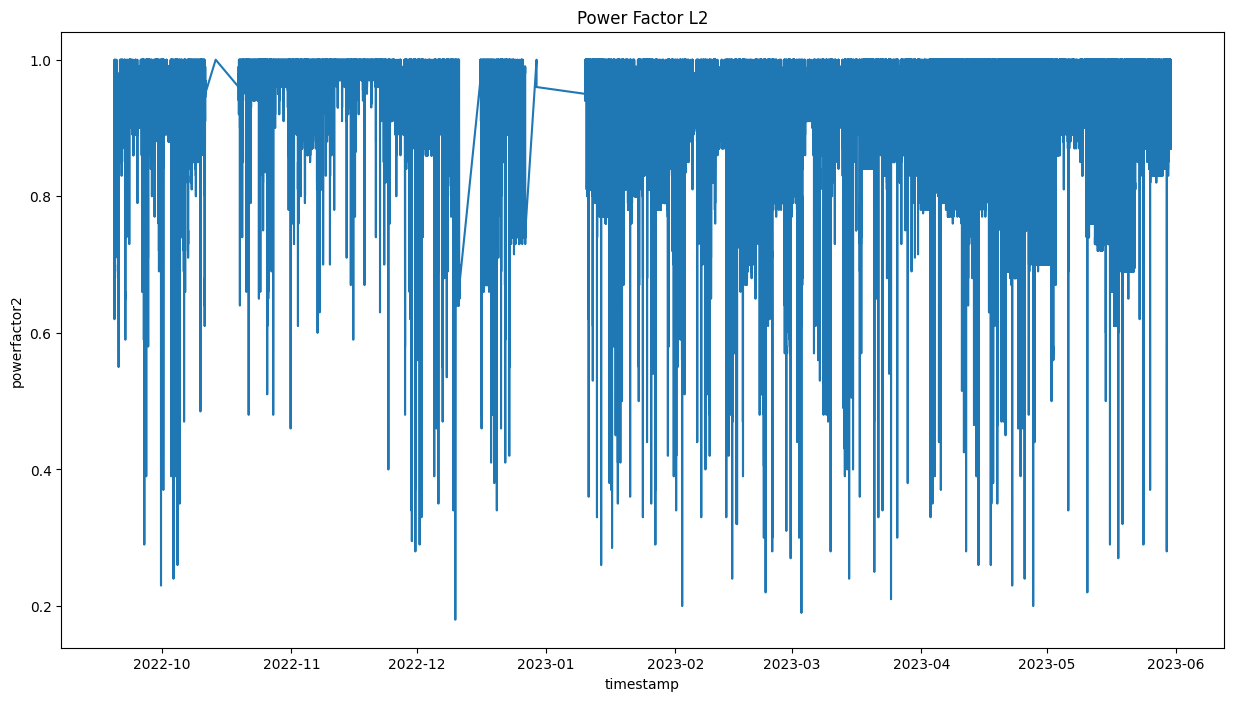

In [77]:
# Plot powerfactor2 if it exists in the dataframe (wasn't dropped due to 0 std)
if 'powerfactor2' in df.columns:
    sns.lineplot(data=df, x='timestamp', y='powerfactor2')
    plt.title('Power Factor L2');

### L3 Phase Analysis

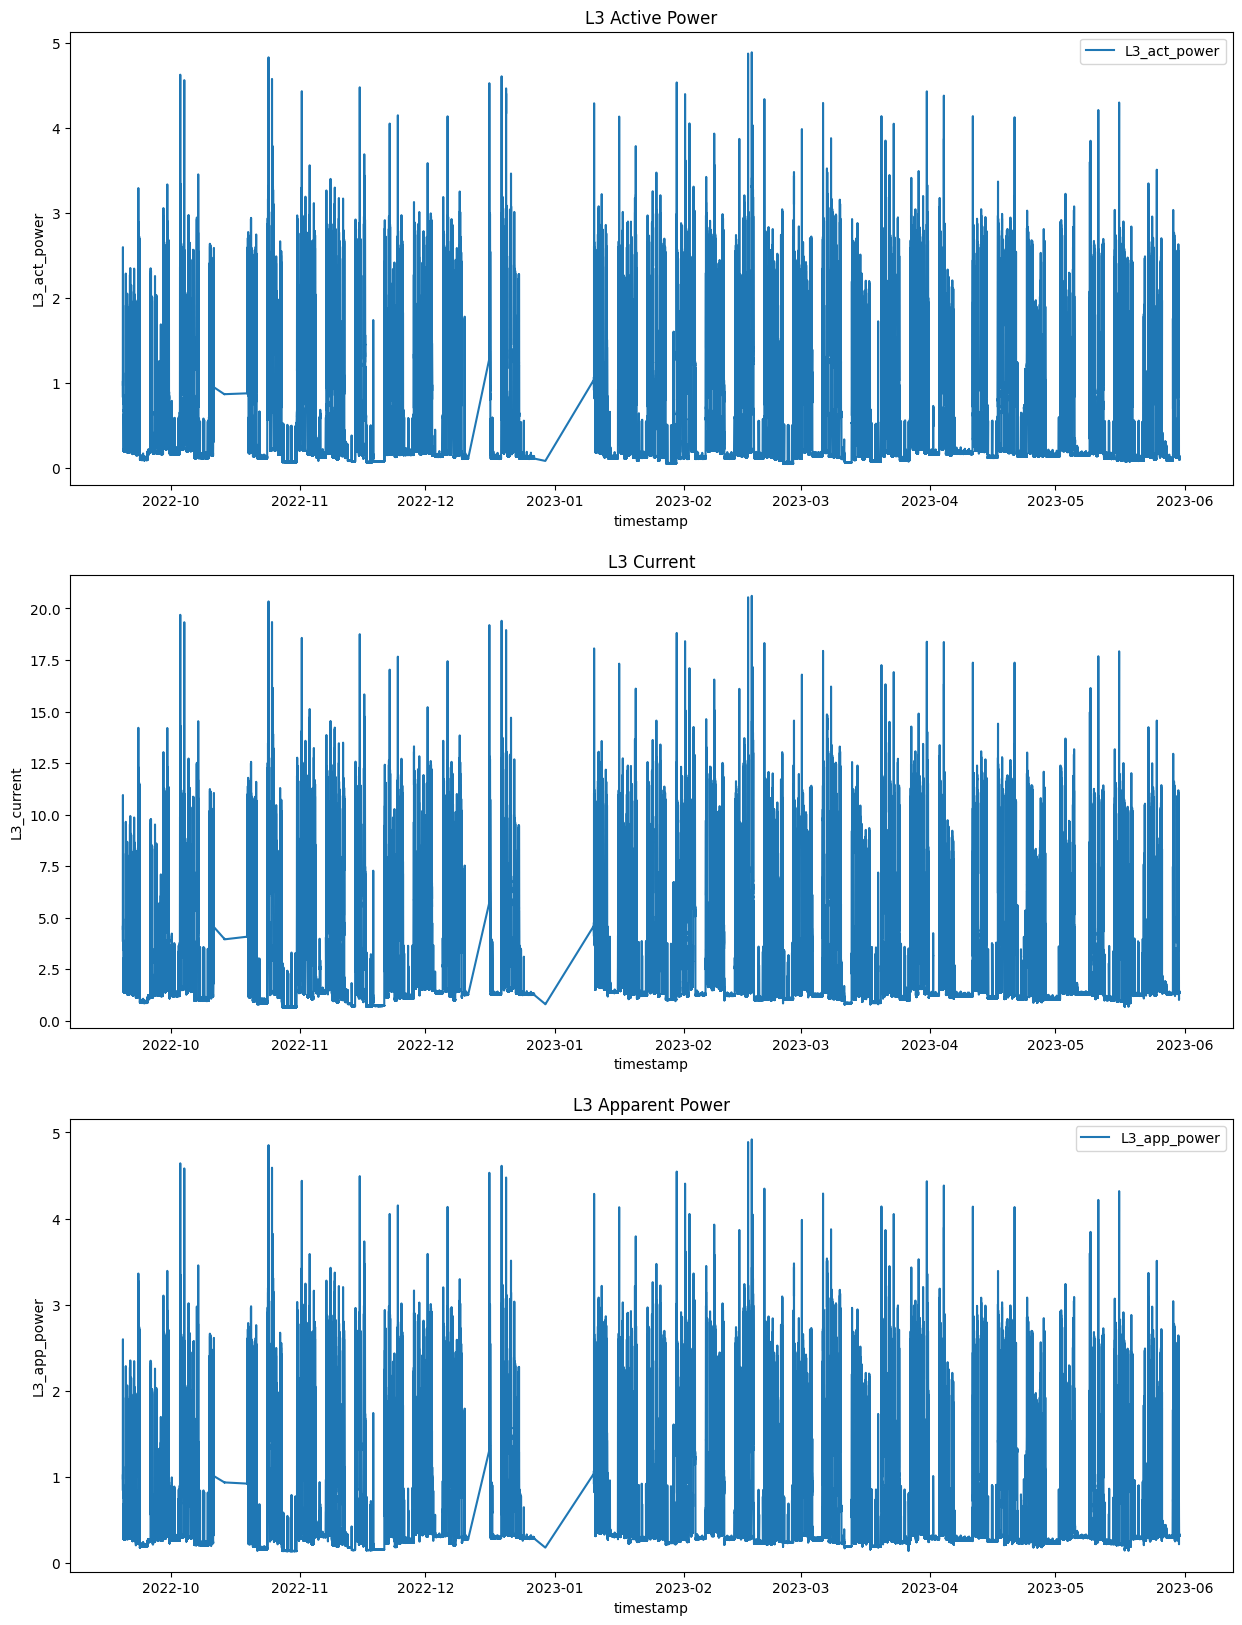

In [78]:
if df.columns.str.contains('L3').any():
    fig, axes = plt.subplots(3, 1, figsize=(15, 20))

    sns.lineplot(data=df, x='timestamp', y='L3_act_power', label='L3_act_power', ax=axes[0])
    axes[0].set_title('L3 Active Power')
    sns.lineplot(data=df, x='timestamp', y='L3_current', ax=axes[1])
    axes[1].set_title('L3 Current')
    sns.lineplot(data=df, x='timestamp', y='L3_app_power', label='L3_app_power', ax=axes[2])
    axes[2].set_title('L3 Apparent Power');
else:
    print('L3-phase columns for this device are uninformative (std = 0)')

MemoryError: Unable to allocate 167. MiB for an array with shape (21886140,) and data type datetime64[ns]

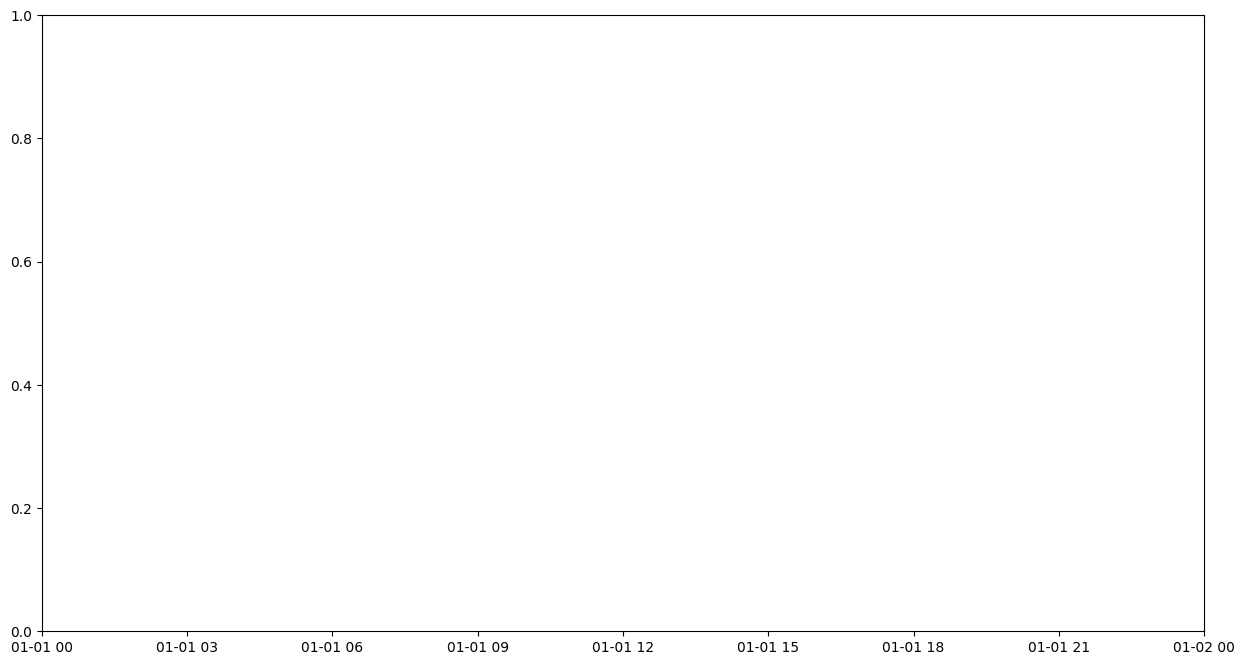

In [79]:
if df.columns.str.contains('L3').any():    
    sns.lineplot(data=df, x='timestamp', y='L3_react_power')
    plt.title('L3 Reactive Power');
else:
    print('L3-phase columns for this device are uninformative (std = 0)')

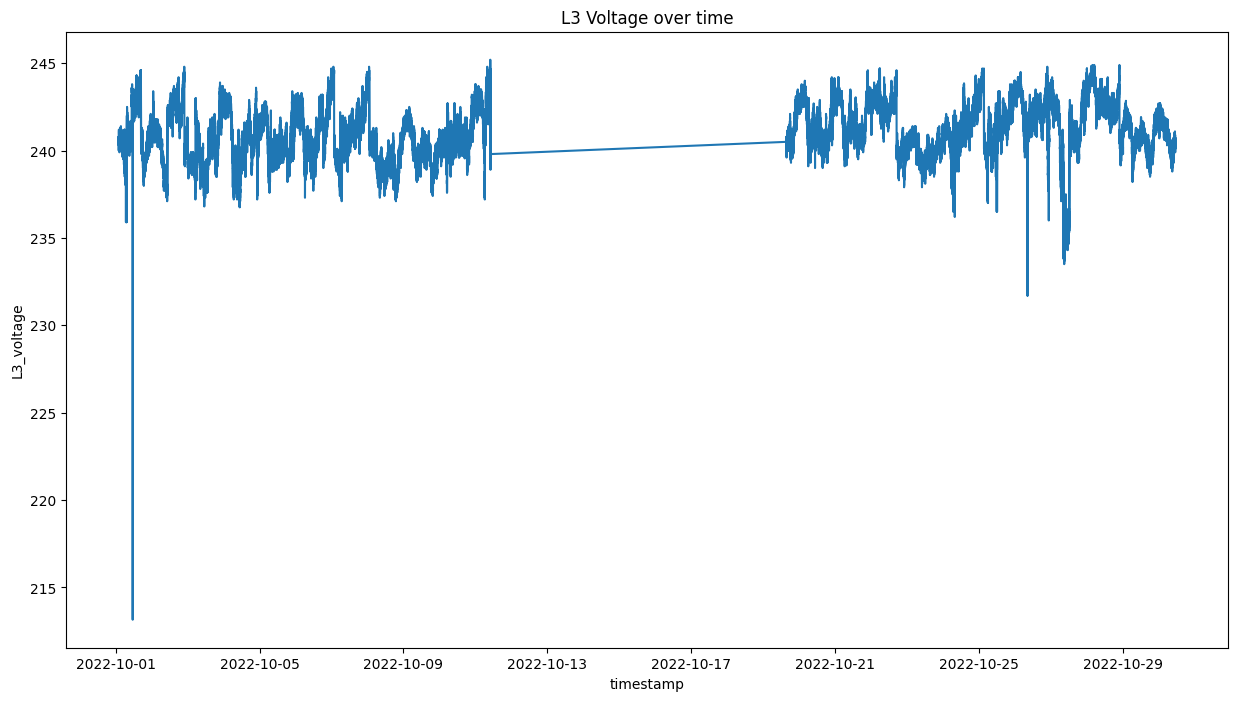

In [ ]:
if df.columns.str.contains('L3').any():    
    sns.lineplot(data=df, x='timestamp', y='L3_voltage')
    plt.title('L3 Voltage over time');
else:
    print('L3-phase columns for this device are uninformative (std = 0)')

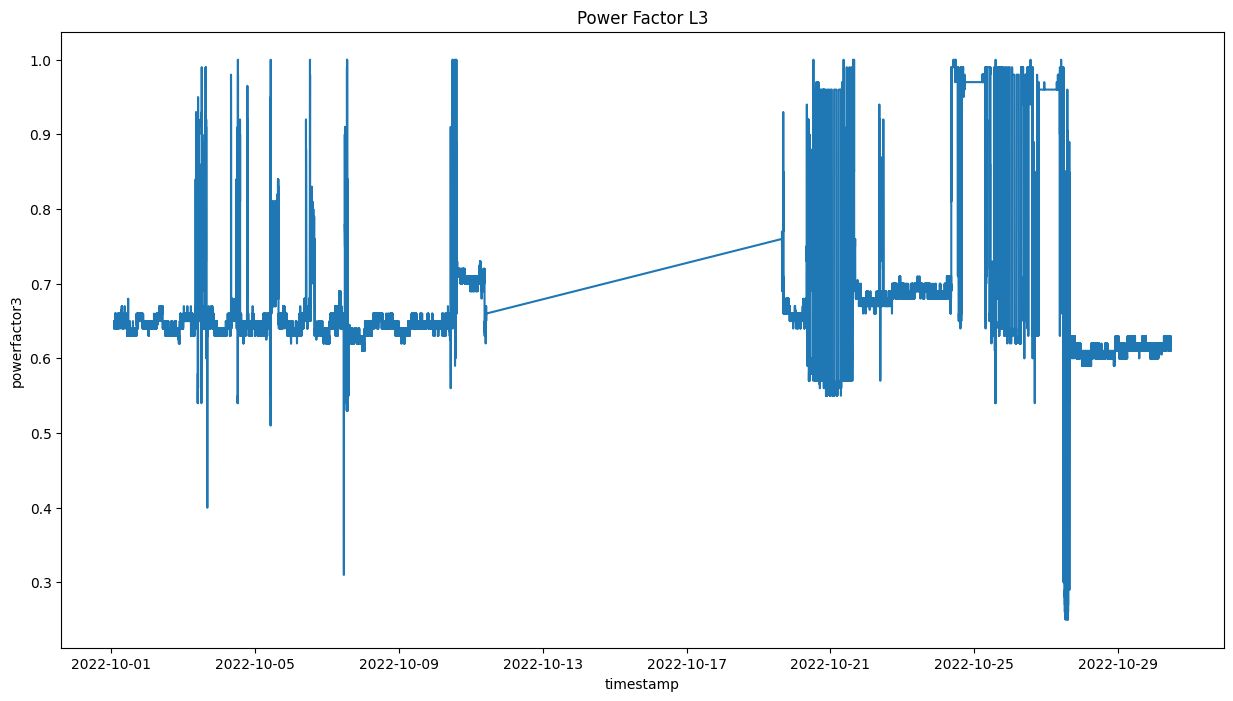

In [ ]:
# Plot powerfactor3 if it exists in the dataframe (wasn't dropped due to 0 std)
if 'powerfactor3' in df.columns:
    sns.lineplot(data=df, x='timestamp', y='powerfactor3')
    plt.title('Power Factor L3');

### Grid Frequency Analysis

Text(0.5, 1.0, 'Grid Frequency')

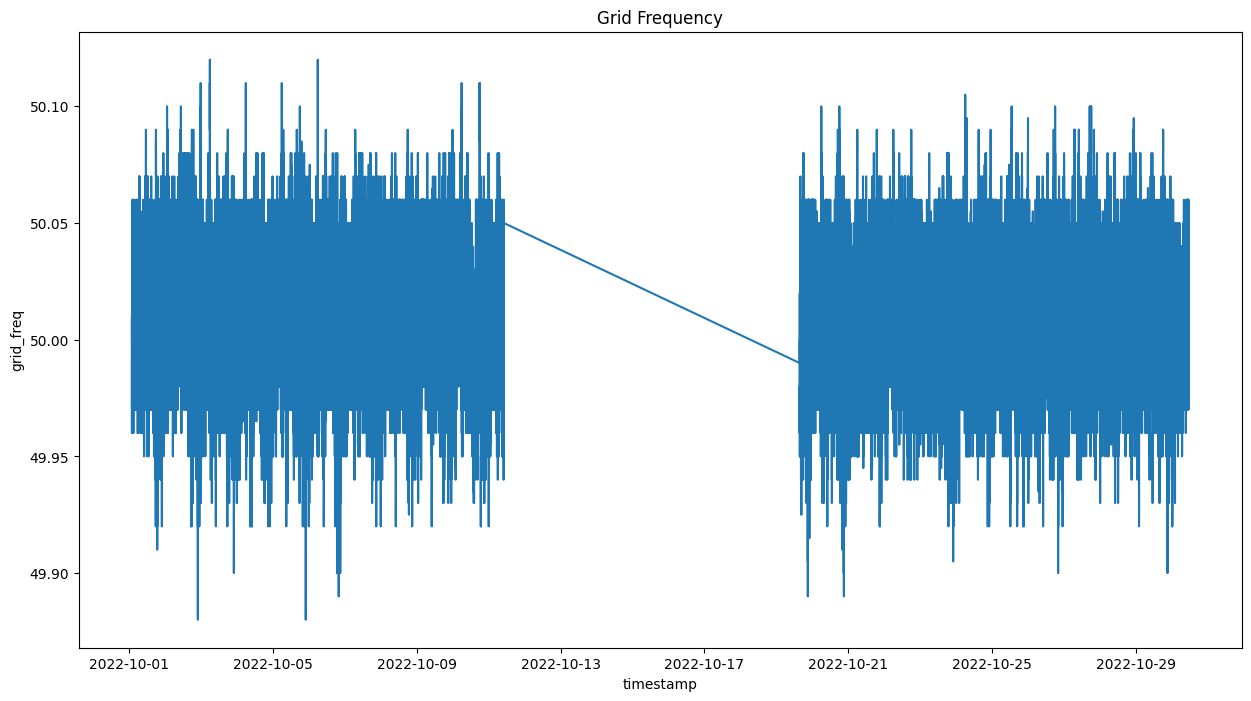

In [ ]:
sns.lineplot(data=df, x='timestamp', y='grid_freq')
plt.title('Grid Frequency')

## Cross-Phase Comparison (if available)

e:\DataScience\Mycroft\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


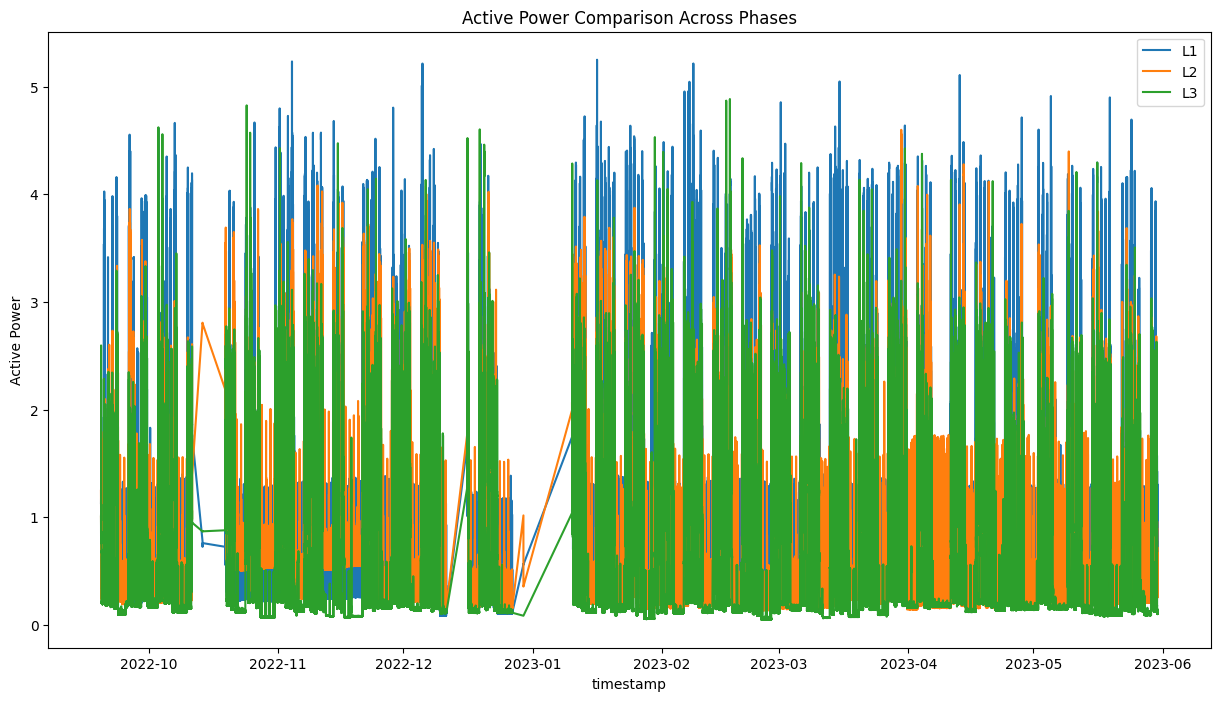

In [80]:
sns.lineplot(data=df, x='timestamp', y='L1_act_power', label='L1')
if 'L2_act_power' in df.columns:
    sns.lineplot(data=df, x='timestamp', y='L2_act_power', label='L2')
else:
    print('L2-phase columns for this device were dropped (std = 0)')
if 'L3_act_power' in df.columns:
    sns.lineplot(data=df, x='timestamp', y='L3_act_power', label='L3')
else:
    print('L3-phase columns for this device were dropped (std = 0)')
    
plt.title('Active Power Comparison Across Phases')
plt.ylabel('Active Power')
plt.legend()
plt.show()

In [ ]:
sns.lineplot(data=df, x='timestamp', y='L1_current', label='L1')
if 'L2_current' in df.columns:
    sns.lineplot(data=df, x='timestamp', y='L2_current', label='L2')
else:
    print('L2-phase columns for this device were dropped (std = 0)')
if 'L3_current' in df.columns:
    sns.lineplot(data=df, x='timestamp', y='L3_current', label='L3')
else:
    print('L3-phase columns for this device were dropped (std = 0)')
    
plt.title('Current Comparison Across Phases')
plt.ylabel('Current')
plt.legend()
plt.show()

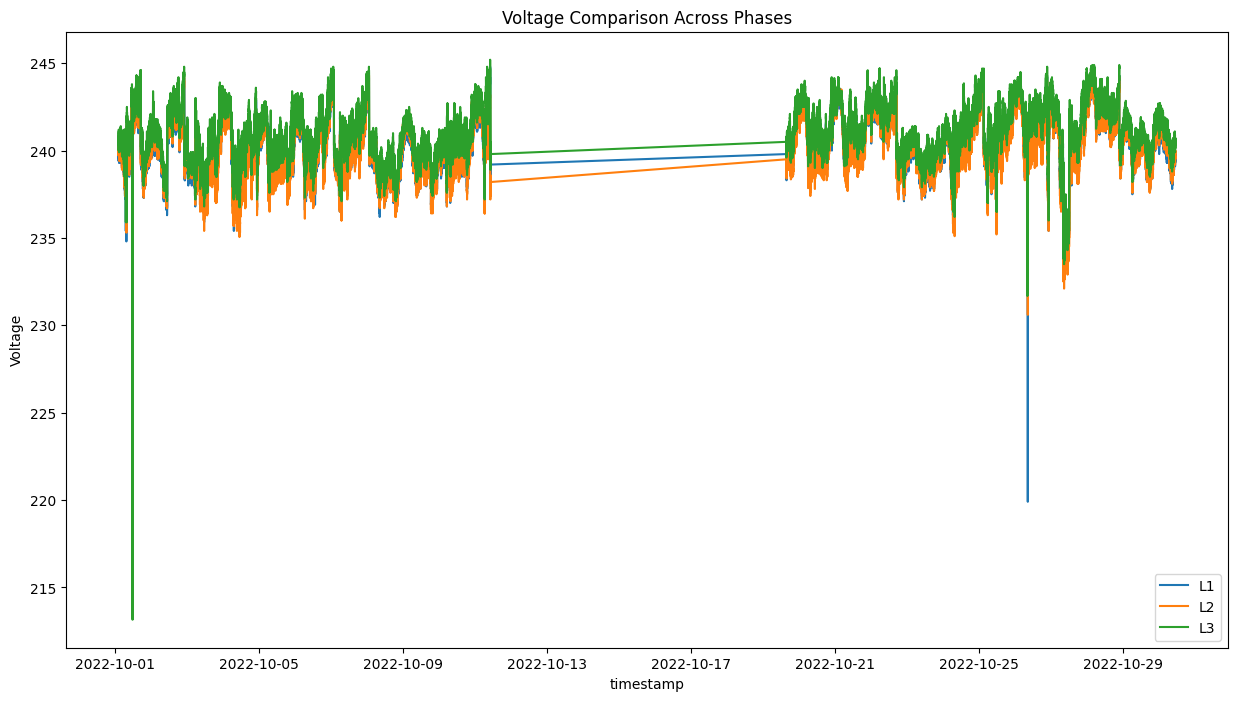

In [ ]:
sns.lineplot(data=df, x='timestamp', y='L1_voltage', label='L1')
if 'L2_voltage' in df.columns:
    sns.lineplot(data=df, x='timestamp', y='L2_voltage', label='L2')
else:
    print('L2-phase columns for this device were dropped (std = 0)')
if 'L3_voltage' in df.columns:
    sns.lineplot(data=df, x='timestamp', y='L3_voltage', label='L3')
else:
    print('L3-phase columns for this device were dropped (std = 0)')
    
plt.title('Voltage Comparison Across Phases')
plt.ylabel('Voltage')
plt.legend()
plt.show()

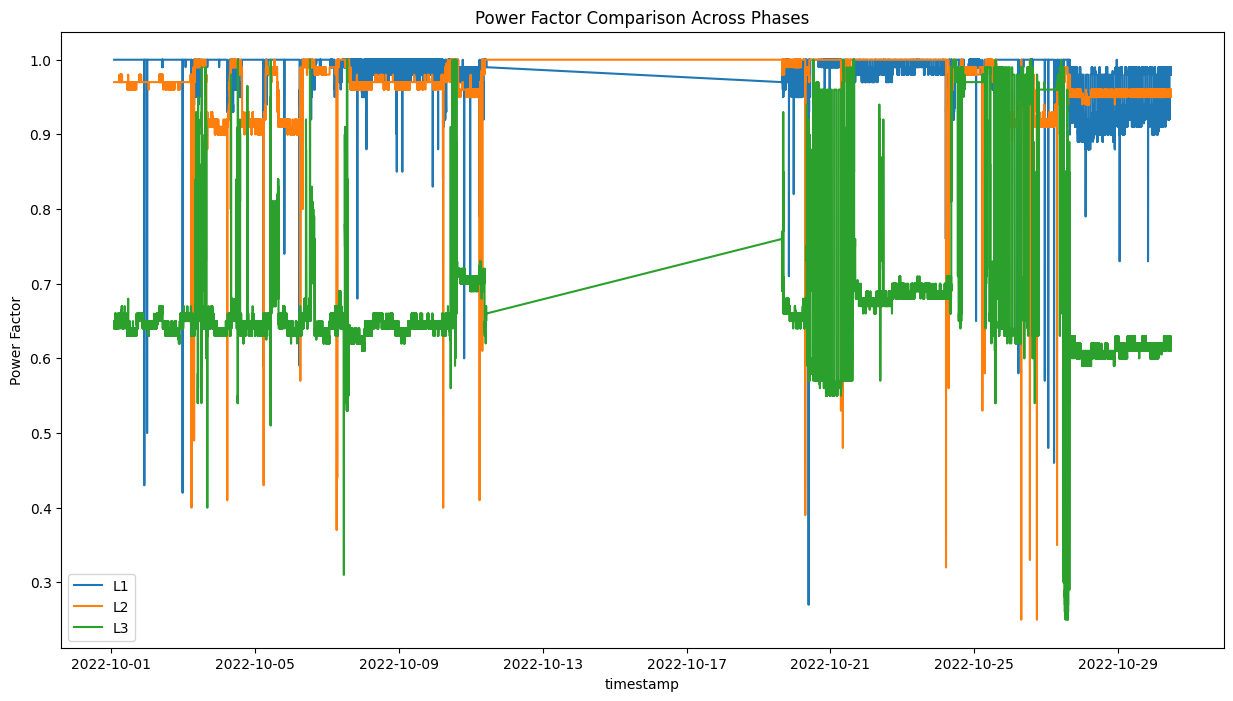

In [ ]:
sns.lineplot(data=df, x='timestamp', y='powerfactor1', label='L1')
if 'powerfactor2' in df.columns:
    sns.lineplot(data=df, x='timestamp', y='powerfactor2', label='L2')
else:
    print('L2-phase columns for this device were dropped (std = 0)')
if 'powerfactor3' in df.columns:
    sns.lineplot(data=df, x='timestamp', y='powerfactor3', label='L3')
else:
    print('L3-phase columns for this device were dropped (std = 0)')
    
plt.title('Power Factor Comparison Across Phases')
plt.ylabel('Power Factor')
plt.legend()
plt.show()

## Hourly Analysis

In [105]:
# Group by hour
df_hour = df.groupby(df['timestamp'].dt.floor('h'))

# Create index for full time range
full_range = pd.DataFrame(
    index=pd.date_range(
        pd.DatetimeIndex(df_hour.indices.keys()).min(),
        pd.DatetimeIndex(df_hour.indices.keys()).max(), 
        freq='h'
    )
)

# Join with hourly aggregated data for each phase
l1_act_pow_hour_endog = full_range.join(df_hour['L1_act_power'].mean(), how='left').squeeze()
if 'L2_act_power' in df.columns:
    l2_act_pow_hour_endog = full_range.join(df_hour['L2_act_power'].mean(), how='left').squeeze()
if 'L3_act_power' in df.columns:
    l3_act_pow_hour_endog = full_range.join(df_hour['L3_act_power'].mean(), how='left').squeeze()

In [ ]:
df_hour.count().describe()

,timestamp,L1_act_power,L1_app_power,L1_current,L1_react_power,L1_voltage,L2_act_power,L2_app_power,L2_current,L2_react_power,L2_voltage,L3_act_power,L3_app_power,L3_current,L3_react_power,L3_voltage,grid_freq,powerfactor1,powerfactor2,powerfactor3,day_of_week,hour
count,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000
mean,2367.958824,2367.958824,2367.958824,2367.958824,2367.958824,2367.958824,2367.958824,2367.958824,2367.958824,2367.958824,2367.958824,2367.958824,2367.958824,2367.958824,2367.958824,2367.958824,2367.958824,2367.958824,2367.958824,2367.958824,2367.958824,2367.958824
std,153.396683,153.396683,153.396683,153.396683,153.396683,153.396683,153.396683,153.396683,153.396683,153.396683,153.396683,153.396683,153.396683,153.396683,153.396683,153.396683,153.396683,153.396683,153.396683,153.396683,153.396683,153.396683
min,376.000000,376.000000,376.000000,376.000000,376.000000,376.000000,376.000000,376.000000,376.000000,376.000000,376.000000,376.000000,376.000000,376.000000,376.000000,376.000000,376.000000,376.000000,376.000000,376.000000,376.000000,376.000000
25%,2372.000000,2372.000000,2372.000000,2372.000000,2372.000000,2372.000000,2372.000000,2372.000000,2372.000000,2372.000000,2372.000000,2372.000000,2372.000000,2372.000000,2372.000000,2372.000000,2372.000000,2372.000000,2372.000000,2372.000000,2372.000000,2372.000000
50%,2384.000000,2384.000000,2384.000000,2384.000000,2384.000000,2384.000000,2384.000000,2384.000000,2384.000000,2384.000000,2384.000000,2384.000000,2384.000000,2384.000000,2384.000000,2384.000000,2384.000000,2384.000000,2384.000000,2384.000000,2384.000000,2384.000000
75%,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
max,3107.000000,3107.000000,3107.000000,3107.000000,3107.000000,3107.000000,3107.000000,3107.000000,3107.000000,3107.000000,3107.000000,3107.000000,3107.000000,3107.000000,3107.000000,3107.000000,3107.000000,3107.000000,3107.000000,3107.000000,3107.000000,3107.000000


In [ ]:
def plot_hourly_data(series, title, color='blue'):
    # Choose a sensible default value for missing data
    fill_value = series.median() if not pd.isna(series.median()) else -100
    
     
    sns.lineplot(series.fillna(fill_value), label=f'hourly {title}', color=color)
    
    # Mark missing values
    plt.scatter(
        x=series[series.isna()].index,
        y=[series.min()-0.01]*series[series.isna()].shape[0],
        color='red',
        marker='x',
        label='missing'
    )
    
    plt.title(f"Hourly {title}")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

### Separate by phase

In [106]:
l1_act_pow_hour_endog.isna().sum()/l1_act_pow_hour_endog.shape[0]

np.float64(0.13571124058547676)

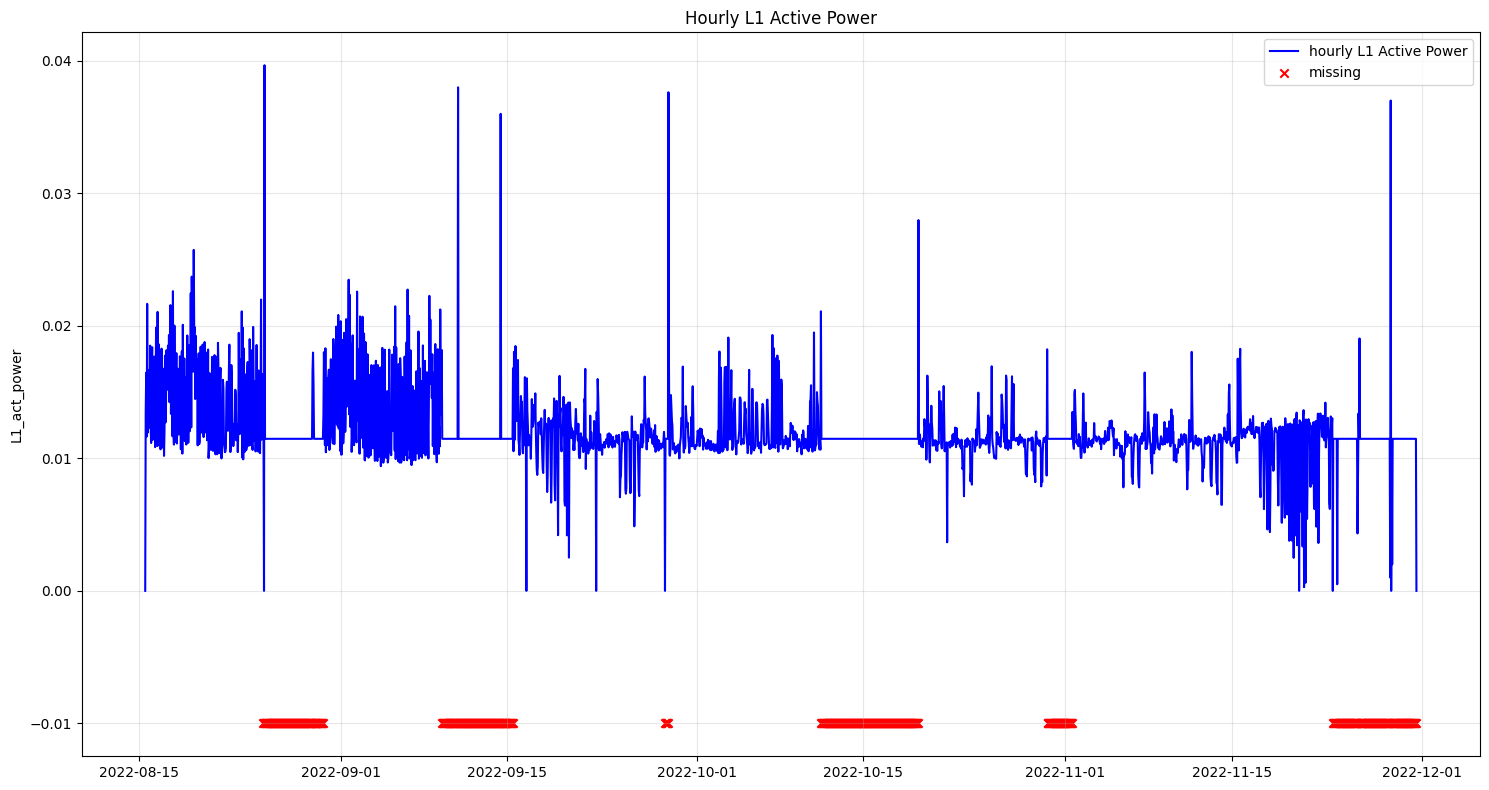

In [50]:
plot_hourly_data(l1_act_pow_hour_endog, 'L1 Active Power')
if 'L2_act_power' in df.columns:
    plot_hourly_data(l2_act_pow_hour_endog, 'L2 Active Power')
if 'L3_act_power' in df.columns:
    plot_hourly_data(l3_act_pow_hour_endog, 'L3 Active Power')

### Cross-phase

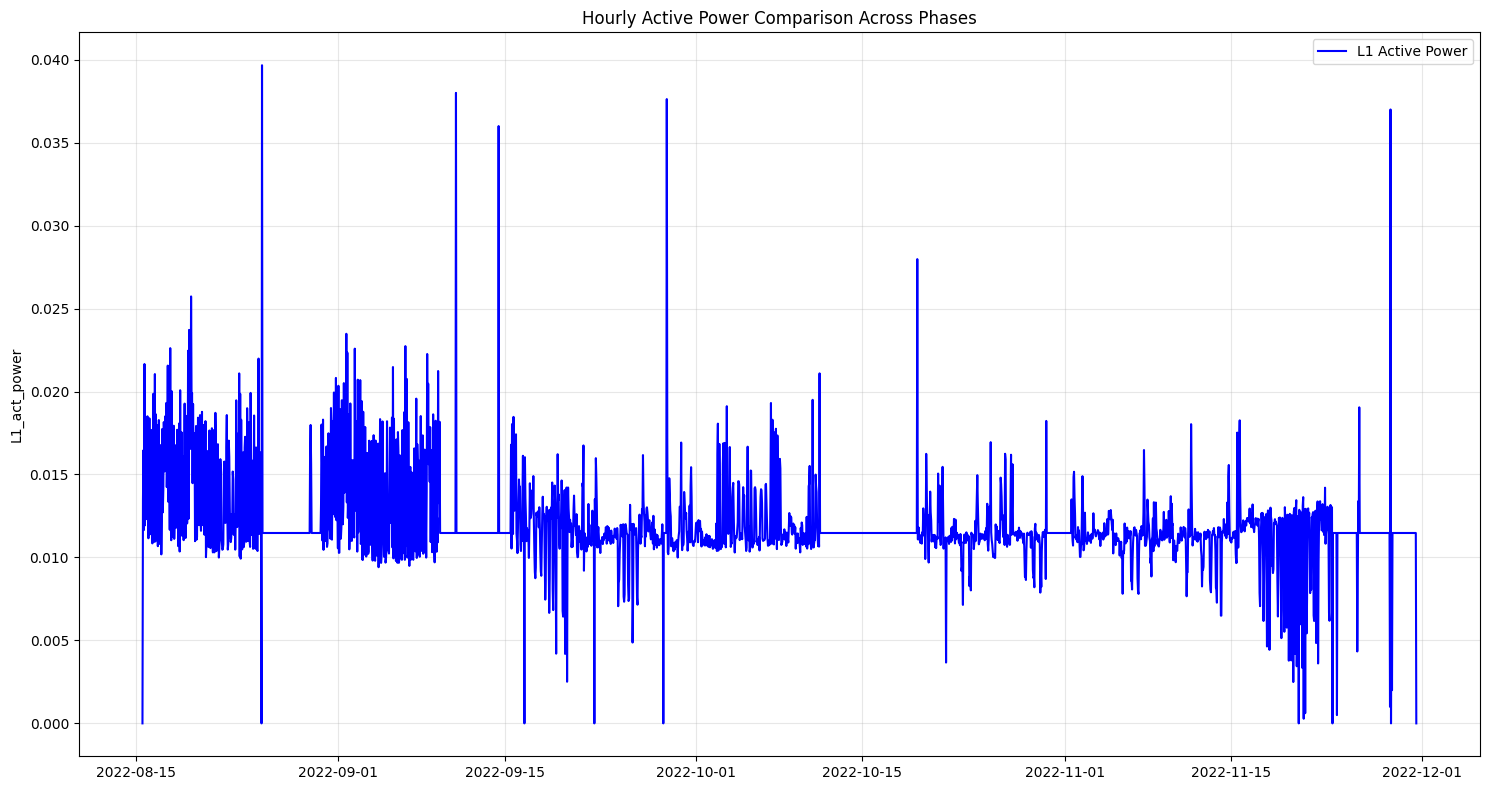

In [51]:
fill_value1 = l1_act_pow_hour_endog.median() if not pd.isna(l1_act_pow_hour_endog.median()) else -100
sns.lineplot(l1_act_pow_hour_endog.fillna(fill_value1), label='L1 Active Power', color='blue')
if 'L2_act_power' in df.columns:
    fill_value2 = l2_act_pow_hour_endog.median() if not pd.isna(l2_act_pow_hour_endog.median()) else -100
    sns.lineplot(l2_act_pow_hour_endog.fillna(fill_value2), label='L2 Active Power', color='green')
if 'L3_act_power' in df.columns:
    fill_value3 = l3_act_pow_hour_endog.median() if not pd.isna(l3_act_pow_hour_endog.median()) else -100
    sns.lineplot(l3_act_pow_hour_endog.fillna(fill_value3), label='L3 Active Power', color='orange')

plt.title("Hourly Active Power Comparison Across Phases")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Cross-phase (smaller time range)

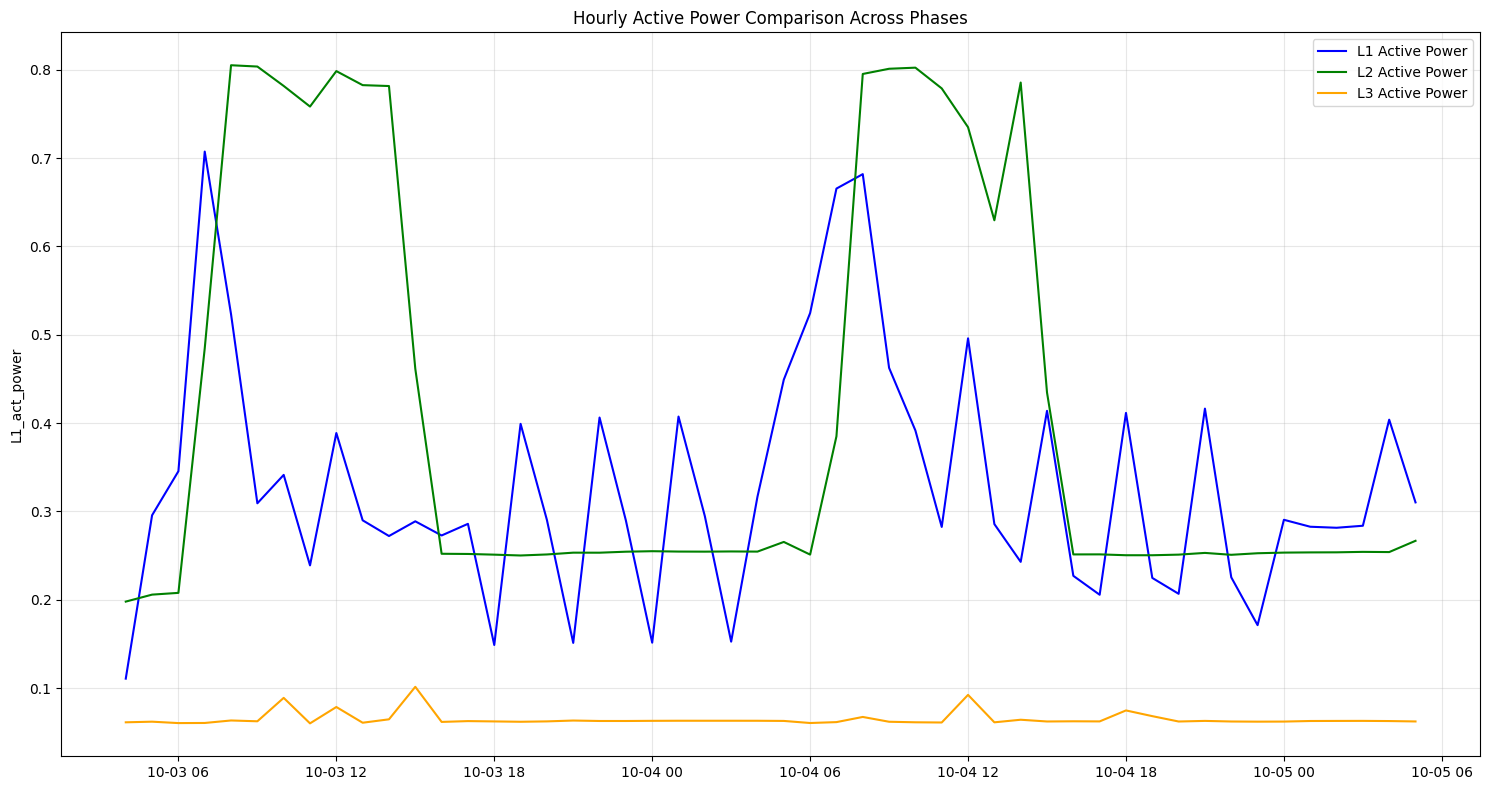

In [ ]:
fill_value1 = l1_act_pow_hour_endog.median() if not pd.isna(l1_act_pow_hour_endog.median()) else -100
sns.lineplot(l1_act_pow_hour_endog.fillna(fill_value1).iloc[50:100], label='L1 Active Power', color='blue')
if 'L2_act_power' in df.columns:
    fill_value2 = l2_act_pow_hour_endog.median() if not pd.isna(l2_act_pow_hour_endog.median()) else -100
    sns.lineplot(l2_act_pow_hour_endog.fillna(fill_value2).iloc[50:100], label='L2 Active Power', color='green')
if 'L3_act_power' in df.columns:
    fill_value3 = l3_act_pow_hour_endog.median() if not pd.isna(l3_act_pow_hour_endog.median()) else -100
    sns.lineplot(l3_act_pow_hour_endog.fillna(fill_value3).iloc[50:100], label='L3 Active Power', color='orange')

plt.title("Hourly Active Power Comparison Across Phases")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Weekly Patterns Analysis (based on hourly analysis)

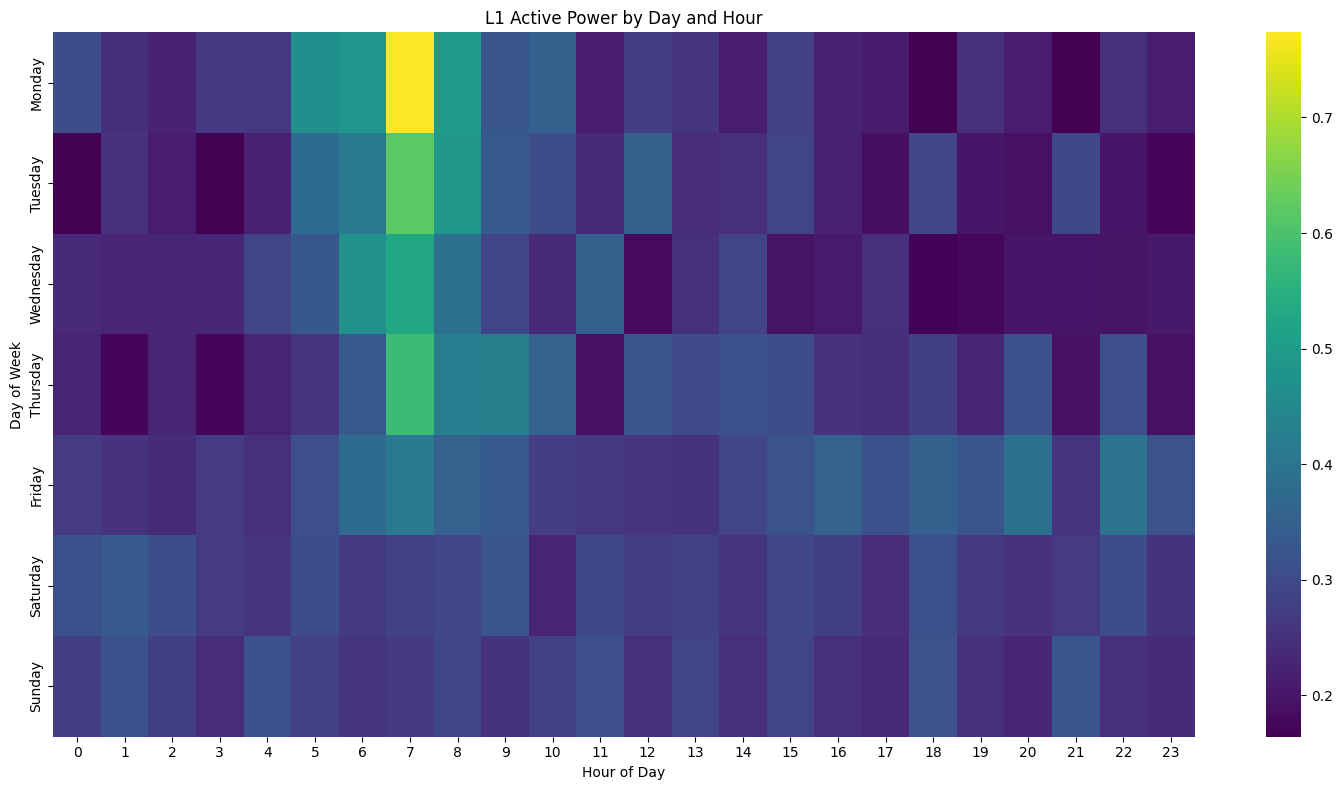

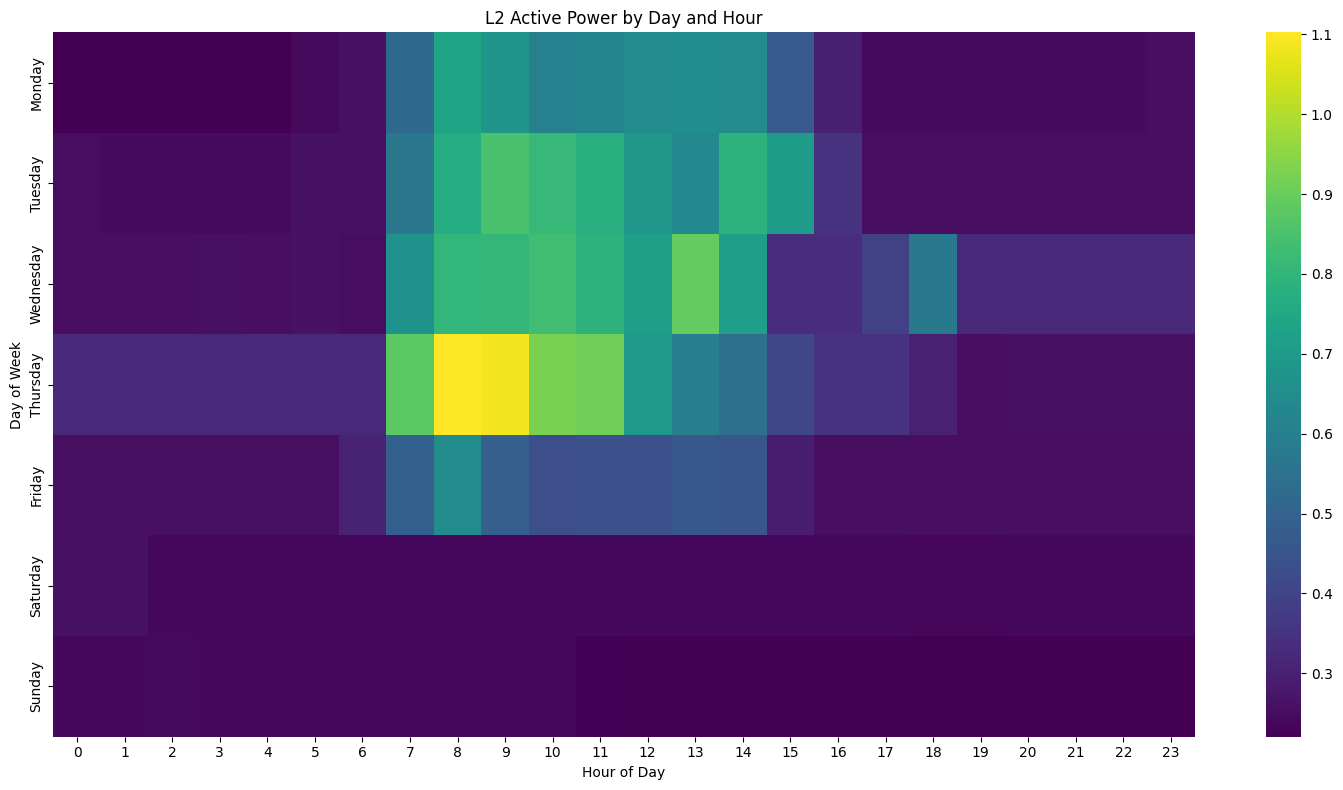

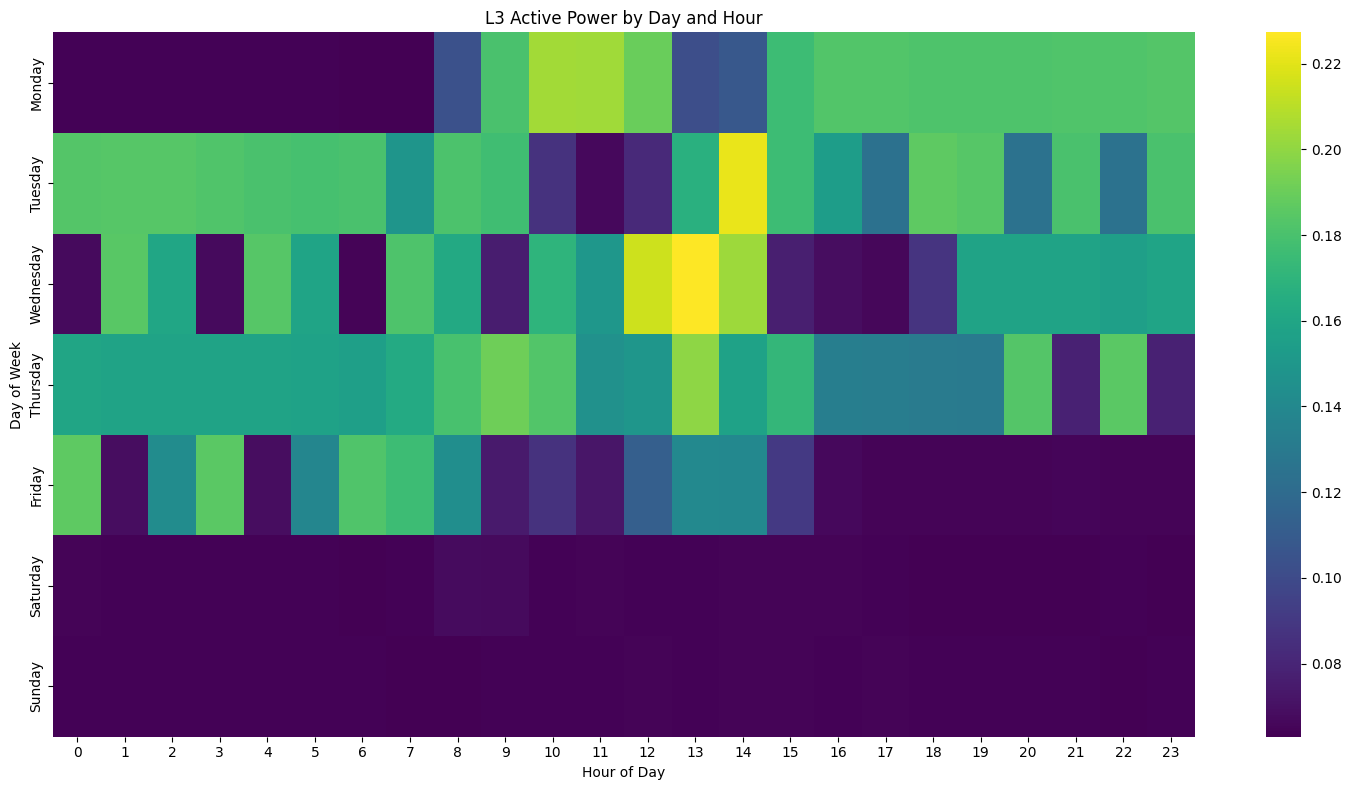

In [ ]:
# Extract day of week and hour
df['day_of_week'] = df['timestamp'].dt.day_name()
df['hour'] = df['timestamp'].dt.hour

# Group by day of week and hour
daily_patterns = df.groupby(['day_of_week', 'hour']).agg({
    'L1_act_power': 'mean',
    'L2_act_power': 'mean',
    'L3_act_power': 'mean'
}).reset_index()

# Order days correctly
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
daily_patterns['day_of_week'] = pd.Categorical(daily_patterns['day_of_week'], categories=day_order, ordered=True)
daily_patterns = daily_patterns.sort_values(['day_of_week', 'hour'])

# Plot heatmap for L1
pivot_table = daily_patterns.pivot(index='day_of_week', columns='hour', values='L1_act_power')
sns.heatmap(pivot_table, cmap='viridis', annot=False)
plt.title('L1 Active Power by Day and Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Day of Week')
plt.tight_layout()
plt.show()

if 'L2_act_power' in df.columns:
    # Plot heatmap for L2
    pivot_table = daily_patterns.pivot(index='day_of_week', columns='hour', values='L2_act_power')
    sns.heatmap(pivot_table, cmap='viridis', annot=False)
    plt.title('L2 Active Power by Day and Hour')
    plt.xlabel('Hour of Day')
    plt.ylabel('Day of Week')
    plt.tight_layout()
    plt.show()

if 'L3_act_power' in df.columns:
    # Plot heatmap for L3
    pivot_table = daily_patterns.pivot(index='day_of_week', columns='hour', values='L3_act_power')
    sns.heatmap(pivot_table, cmap='viridis', annot=False)
    plt.title('L3 Active Power by Day and Hour')
    plt.xlabel('Hour of Day')
    plt.ylabel('Day of Week')
    plt.tight_layout()
    plt.show()

## Autocorrelation Analysis

<Figure size 1500x600 with 0 Axes>

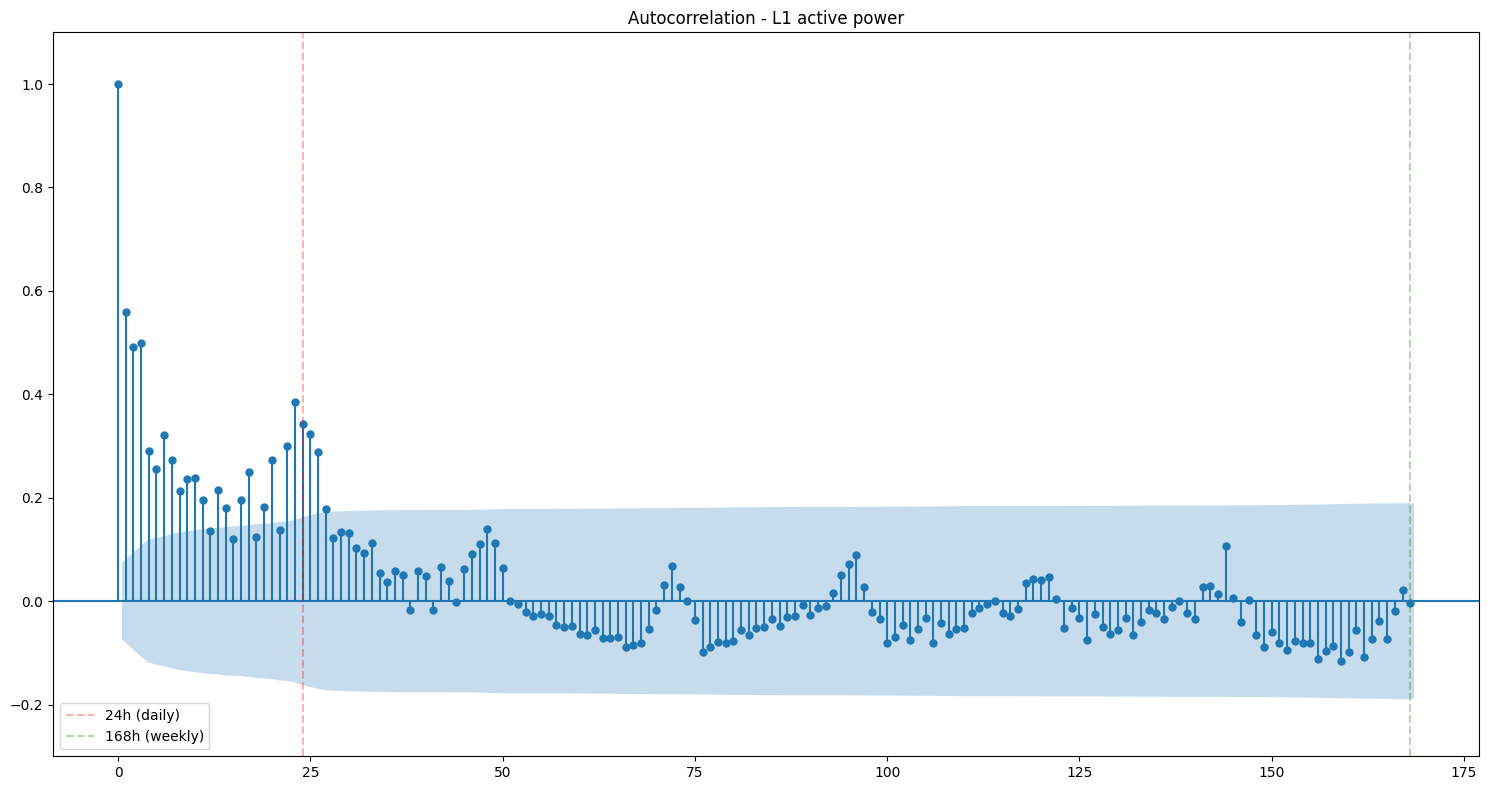

<Figure size 1500x600 with 0 Axes>

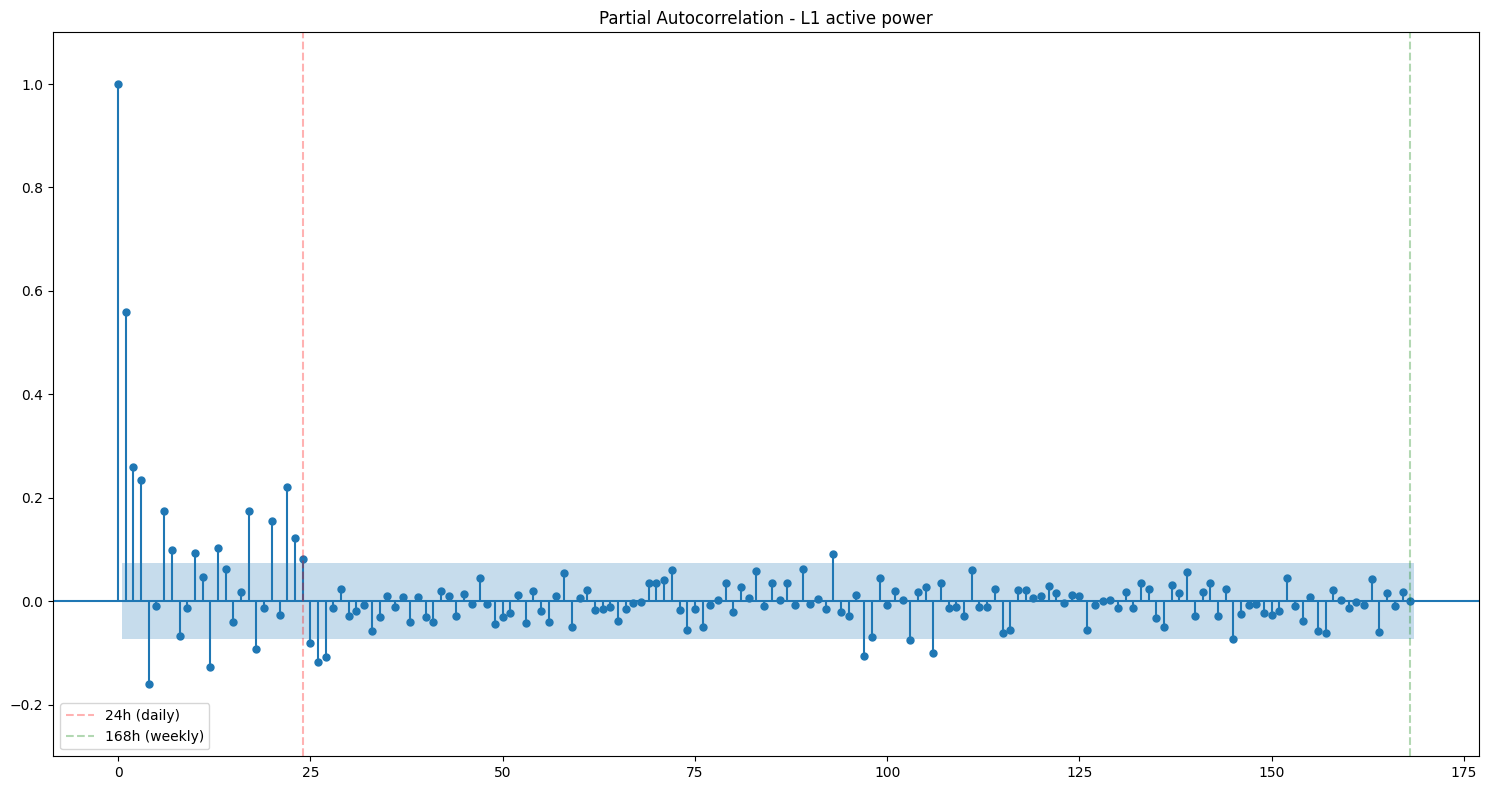

In [43]:
# Autocorrelation
plt.figure(figsize=(15, 6))
plot_acf(l1_act_pow_hour_endog.fillna(l1_act_pow_hour_endog.median()), lags=24*7, 
            title=f'Autocorrelation - L1 active power')
plt.ylim(-0.3, 1.1)
plt.axvline(x=24, color='r', linestyle='--', alpha=0.3, label='24h (daily)')
plt.axvline(x=24*7, color='g', linestyle='--', alpha=0.3, label='168h (weekly)')
plt.legend()
plt.tight_layout()
plt.show()

# Partial autocorrelation
plt.figure(figsize=(15, 6))
plot_pacf(l1_act_pow_hour_endog.fillna(l1_act_pow_hour_endog.median()), lags=24*7, 
            title=f'Partial Autocorrelation - L1 active power')
plt.ylim(-0.3, 1.1)
plt.axvline(x=24, color='r', linestyle='--', alpha=0.3, label='24h (daily)')
plt.axvline(x=24*7, color='g', linestyle='--', alpha=0.3, label='168h (weekly)')
plt.legend()
plt.tight_layout()
plt.show()